# Final project: classification as sensemaking, by facet

This notebook follows the HW3 structure, adapted to the final project. Instead of one label per photo, each of the 300 hand-labeled photos has a label in **four hand-labeled facets** (from the project doc):

* **physical_setting**: Indoor | Coastal | Urban | Nature
* **activity**: Putting myself in the frame | Sharing the experience | Tasting the location | Everyday life | Documenting the location
* **subject**: Built | Nature | Food & Drink | Objects & Text | People | None/Other
* **place_recognizable**: Obvious | Hint | None

A separate bag-of-words logistic regression is trained **for each facet**, using the photo's caption as its text. Every part below runs once per facet, so each output is headed with the facet name.

**How to use this notebook.** Set Part 1, then run it top to bottom.

**AI policy.** AI can help with code but not with interpretation, analysis or writing. The code in this notebook was written with AI help; check that it does what you say it does.

## Part 0: Setup

In [1]:
import os, csv, math, re
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

try:
    display
except NameError:          # outside Jupyter/Colab
    display = print

pd.set_option("display.max_colwidth", 120)

## Part 1: Load your data

The labels come straight from the **Final Project - Natalie Crawford** Google Sheet (tab `photo_facets`). Set `SOURCE`:

* `"sheet"`: read the Google Sheet directly (Colab asks you to sign in with the Berkeley account that owns the sheet).
* `"csv"`: a CSV export of the same tab (`File > Download > Comma-separated values` in Sheets), uploaded to Colab or on Drive.

Only rows with `in_sample == "yes"` (the 300 hand-labeled photos) are used.

Images are optional and only used to show thumbnails next to results. If `IMAGES_ZIP` exists it is unzipped; if images can't be found, everything still runs and just prints tables.

In [2]:
SOURCE = "sheet"                                   # "sheet" or "csv"
SHEET_ID = "1wJY0isRNJv-HuNG0TYGgxRtOq4JgFo3LK8idF3mxyu0"
SHEET_TAB = "photo_facets"
CSV_PATH = "/content/drive/MyDrive/INFO/202/photo_facets.csv"    # used if SOURCE == "csv"

IMAGES_ZIP = "/content/drive/MyDrive/INFO/202/images.zip"       # same zip as HW3; set to None to skip images
IMAGE_DIR = "/content/images/images"

TEXT_COL = "Caption"     # the caption column in the sheet
FACETS = ["physical_setting", "activity", "subject", "place_recognizable"]
# Metadata facets can be added too, e.g. FACETS += ["time_of_day", "country"]

RANDOM_STATE = 0

In [3]:
IN_COLAB = "google.colab" in str(get_ipython()) if "get_ipython" in globals() else False

if IN_COLAB and ((IMAGES_ZIP and IMAGES_ZIP.startswith("/content/drive")) or CSV_PATH.startswith("/content/drive")):
    from google.colab import drive
    drive.mount("/content/drive")

if SOURCE == "sheet":
    from google.colab import auth
    auth.authenticate_user()
    import gspread
    from google.auth import default
    creds, _ = default()
    gc = gspread.authorize(creds)
    values = gc.open_by_key(SHEET_ID).worksheet(SHEET_TAB).get_all_values()
    header, rows = values[0], values[1:]
    rows = [r + [""] * (len(header) - len(r)) for r in rows]
    raw = pd.DataFrame(rows, columns=header)
elif SOURCE == "csv":
    raw = pd.read_csv(CSV_PATH, dtype=str, keep_default_na=False)
else:
    raise ValueError("SOURCE must be 'sheet' or 'csv'")

raw = raw.apply(lambda col: col.str.strip() if col.dtype == object else col)
df = raw[raw.in_sample.str.lower() == "yes"].reset_index(drop=True)
df["text"] = df[TEXT_COL].str.replace("\t", " ").str.replace("\n", " ")
print(len(raw), "photos in the sheet;", len(df), "hand-labeled (in_sample == yes)")

missing_text = (df.text == "").sum()
assert missing_text == 0, f"{missing_text} sampled photos have no caption"
for f in FACETS:
    blank = (df[f] == "").sum()
    print(f"{f}: {blank} blank labels")

Mounted at /content/drive
485 photos in the sheet; 300 hand-labeled (in_sample == yes)
physical_setting: 0 blank labels
activity: 0 blank labels
subject: 0 blank labels
place_recognizable: 0 blank labels


In [4]:
# Images (optional)
if IMAGES_ZIP and os.path.exists(IMAGES_ZIP) and not os.path.exists(IMAGE_DIR):
    os.system(f'unzip -oq "{IMAGES_ZIP}" -d /content/images')

def find_image(fn):
    for name in (fn, os.path.splitext(fn)[0] + ".JPG", os.path.splitext(fn)[0] + ".jpg", os.path.splitext(fn)[0] + ".jpeg"):
        p = os.path.join(IMAGE_DIR, name)
        if os.path.exists(p):
            return p
    return None

df["path"] = [find_image(fn) for fn in df.filename]
HAVE_IMAGES = df.path.notna().all()
print("Images found:", df.path.notna().sum(), "of", len(df), "| showing images:", HAVE_IMAGES)

Images found: 300 of 300 | showing images: True


**Check the labels against the codebook.** This lists any label that isn't one of the allowed values for its facet (typos, or a value from the wrong column). Fix them in the sheet, or map them with `LABEL_FIXES` in the next cell.

In [5]:
ALLOWED = {
    "physical_setting": ["Indoor", "Coastal", "Urban", "Nature"],
    "activity": ["Putting myself in the frame", "Sharing the experience", "Tasting the location",
                 "Everyday life", "Documenting the location"],
    "subject": ["Built", "Nature", "Food & Drink", "Objects & Text", "People", "None/Other"],
    "place_recognizable": ["Obvious", "Hint", "None"],
}
for f in FACETS:
    if f not in ALLOWED:
        continue
    bad = df[~df[f].isin(ALLOWED[f])]
    if len(bad):
        print(f"== {f}: {len(bad)} label(s) not in the codebook")
        display(bad[["filename", f, "text"]])

In [6]:
# Optional relabeling, applied before training. Example:
# LABEL_FIXES = {"subject": {"None": "None/Other"}}
LABEL_FIXES = {}

for f, mapping in LABEL_FIXES.items():
    df[f] = df[f].replace(mapping)

# Cross-validation needs every class to have at least N_FOLDS items. Classes smaller than
# MIN_CLASS_SIZE are left out of that facet's model (and listed here) rather than crashing.
N_FOLDS = 5
MIN_CLASS_SIZE = N_FOLDS

data = {}    # facet -> dataframe of the items used for that facet
for f in FACETS:
    counts = df[f].value_counts()
    small = counts[counts < MIN_CLASS_SIZE]
    if len(small):
        print(f"{f}: leaving out {small.sum()} item(s) in classes with < {MIN_CLASS_SIZE} items: {small.to_dict()}")
    sub = df[df[f].isin(counts[counts >= MIN_CLASS_SIZE].index)].copy()
    sub["label"] = sub[f]
    data[f] = sub.reset_index(drop=True)

Captions. The sheet already has a caption per photo (the same captions as `captions.tsv`, used for BM25), so this notebook uses those instead of re-running BLIP. If you'd rather use BLIP captions as in HW3, run the optional cell below: it replaces `text` with a BLIP caption (needs the images and a GPU runtime). As in HW3, read at least 20 captions next to their images and note where they're wrong.

In [7]:
USE_BLIP = False

if USE_BLIP:
    import torch
    from transformers import BlipProcessor, BlipForConditionalGeneration
    from PIL import Image
    assert HAVE_IMAGES, "BLIP needs the images"
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    processor = BlipProcessor.from_pretrained("Salesforce/blip-image-captioning-base")
    blip = BlipForConditionalGeneration.from_pretrained("Salesforce/blip-image-captioning-base").to(device)
    caps = []
    for i in range(0, len(df), 16):
        imgs = [Image.open(p).convert("RGB") for p in df.path[i:i + 16]]
        inputs = processor(imgs, return_tensors="pt").to(device)
        with torch.no_grad():
            out = blip.generate(**inputs, max_new_tokens=30, do_sample=False, num_beams=1)
        caps.extend(processor.batch_decode(out, skip_special_tokens=True))
    blip_text = dict(zip(df.filename, caps))
    for f in FACETS:
        data[f]["text"] = data[f].filename.map(blip_text)

In [8]:
# A helper for looking at images (does nothing if the images weren't found)
from PIL import Image

def show_images(sub, titles=None, ncols=4, size=3):
    if not HAVE_IMAGES or len(sub) == 0:
        return
    paths = list(sub.path)
    nrows = math.ceil(len(paths) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for k, p in enumerate(paths):
        ax = axes.flat[k]
        ax.imshow(Image.open(p).convert("RGB"))
        if titles is not None:
            ax.set_title(titles[k], fontsize=8)
    plt.tight_layout()
    plt.show()

### Look at your data
How many examples are in each class of each facet? Read a few from each class.

In [9]:
for f in FACETS:
    d = data[f]
    print("=" * 25, f, "=" * 25)
    print(d.label.value_counts().to_string())
    print()
    for label in sorted(d.label.unique()):
        print("==", label)
        texts = d[d.label == label].text
        for t in texts.sample(min(3, len(texts)), random_state=RANDOM_STATE):
            print("   ", t[:200])
    print()

========================= physical_setting =========================
label
Urban      109
Indoor      95
Coastal     49
Nature      47

== Coastal
    Looking down a narrow calanque inlet lined with moored sailboats and pine forest.
    A dark sand beach dotted with people near the water under a blue sky with wispy clouds.
    Two smiling friends take a selfie on the Old Port promenade with Notre-Dame de la Garde in the distance.
== Indoor
    View from inside a crowded bus as it passes another SITA bus on a narrow coastal road.
    Two cups of affogato-style dessert from Vivoli gelateria on a bright blue table.
    Museum display cases showing 'Love Me Do' vinyl records in a red Beatles exhibit.
== Nature
    Friends walk along a leafy suburban road on a partly cloudy day.
    Three friends stand together in a rose garden under a blue sky with puffy clouds.
    Rose-covered arches over a curving path in the Rosaleda rose garden of Retiro Park.
== Urban
    Two friends in sunglasses ta

How the facets line up with each other (counts of photos with each pair of labels). Useful for seeing which facets carry overlapping information.

In [10]:
import itertools
for f1, f2 in itertools.combinations(FACETS, 2):
    print("==", f1, "x", f2)
    display(pd.crosstab(df[f1], df[f2]))

== physical_setting x activity


activity,Documenting the location,Everyday life,Putting myself in the frame,Sharing the experience,Tasting the location
physical_setting,,,,,
Coastal,27,0,9,12,1
Indoor,30,4,6,17,38
Nature,26,1,10,9,1
Urban,66,3,18,12,10


== physical_setting x subject


subject,Built,Food & Drink,Nature,None/Other,Objects & Text,People
physical_setting,,,,,,
Coastal,6,1,20,0,3,19
Indoor,17,37,0,5,14,22
Nature,6,1,19,0,5,16
Urban,55,10,3,1,13,27


== physical_setting x place_recognizable


place_recognizable,Hint,None,Obvious
physical_setting,,,
Coastal,12,23,14
Indoor,20,72,3
Nature,12,33,2
Urban,33,54,22


... (2 outputs left out)

== activity x place_recognizable


place_recognizable,Hint,None,Obvious
activity,,,
Documenting the location,48,77,24
Everyday life,0,8,0
Putting myself in the frame,9,22,12
Sharing the experience,6,40,4
Tasting the location,14,35,1


== subject x place_recognizable


place_recognizable,Hint,None,Obvious
subject,,,
Built,30,35,19
Food & Drink,14,34,1
Nature,9,30,3
None/Other,0,6,0
Objects & Text,12,20,3
People,12,57,15


## Part 2: Train a classifier for each facet

Same model as HW3: a binary bag-of-words over the caption, and a logistic regression. Cross-validation gives every photo a prediction from a model that never saw it in training. One model is trained per facet.

In [11]:
NGRAM_RANGE = (1, 1)     # (1, 1) = single words; (1, 2) = words and two-word phrases
MIN_DF = 2               # ignore features that occur in fewer than this many documents
C = 1.0                  # regularization: smaller = simpler model, larger = more complex

def make_model():
    return Pipeline([
        ("vec", CountVectorizer(lowercase=True, binary=True, ngram_range=NGRAM_RANGE, min_df=MIN_DF,
                                token_pattern=r"[A-Za-z0-9']+")),
        ("clf", LogisticRegression(C=C, solver="lbfgs", max_iter=10000)),
    ])

R = {}       # facet -> everything computed for that facet
summary = []
for f in FACETS:
    d = data[f]
    X = d.text.to_list()
    y = np.array(d.label.to_list())
    classes = np.unique(y)
    n_splits = min(N_FOLDS, Counter(y).most_common()[-1][1])
    assert n_splits >= 2, f"{f}: need at least 2 examples of every class"
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    probs = cross_val_predict(make_model(), X, y, cv=cv, method="predict_proba")
    pred = classes[probs.argmax(axis=1)]

    ci = {c: i for i, c in enumerate(classes)}
    d["pred"] = pred
    d["p_true"] = [probs[i, ci[l]] for i, l in enumerate(d.label)]
    d["p_pred"] = probs.max(axis=1)

    majority = Counter(y).most_common(1)[0]
    R[f] = dict(X=X, y=y, classes=classes, probs=probs, pred=pred)
    summary.append({"facet": f, "n items": len(y), "n classes": len(classes),
                    "majority class": majority[0], "majority baseline": majority[1] / len(y),
                    "CV accuracy": (pred == y).mean()})

summary = pd.DataFrame(summary).set_index("facet")
display(summary.round(3))

,n items,n classes,majority class,majority baseline,CV accuracy
facet,,,,,
physical_setting,300,4,Urban,0.363,0.707
activity,300,5,Documenting the location,0.497,0.857
subject,300,6,People,0.280,0.743
place_recognizable,300,3,None,0.607,0.593


Per-class performance for each facet (precision, recall and F1). A class that's hard for the model may be telling you something about the class.

In [12]:
for f in FACETS:
    y, pred, classes = R[f]["y"], R[f]["pred"], R[f]["classes"]
    print("=" * 25, f, "=" * 25)
    report = pd.DataFrame(classification_report(y, pred, output_dict=True, zero_division=0)).T
    display(report.loc[list(classes) + ["macro avg"], ["precision", "recall", "f1-score", "support"]].round(3))

========================= physical_setting =========================


,precision,recall,f1-score,support
Coastal,0.833,0.714,0.769,49.0
Indoor,0.679,0.800,0.734,95.0
Nature,0.710,0.468,0.564,47.0
Urban,0.687,0.725,0.705,109.0
macro avg,0.727,0.677,0.693,300.0


========================= activity =========================


,precision,recall,f1-score,support
Documenting the location,0.825,0.946,0.881,149.0
Everyday life,0.000,0.000,0.000,8.0
Putting myself in the frame,0.851,0.930,0.889,43.0
Sharing the experience,0.975,0.780,0.867,50.0
Tasting the location,0.881,0.740,0.804,50.0
macro avg,0.706,0.679,0.688,300.0


========================= subject =========================


,precision,recall,f1-score,support
Built,0.694,0.893,0.781,84.0
Food & Drink,0.800,0.816,0.808,49.0
Nature,0.517,0.357,0.423,42.0
None/Other,0.000,0.000,0.000,6.0
Objects & Text,0.536,0.429,0.476,35.0
People,0.918,0.929,0.923,84.0
macro avg,0.578,0.571,0.569,300.0


========================= place_recognizable =========================


,precision,recall,f1-score,support
Hint,0.286,0.182,0.222,77.0
None,0.661,0.824,0.733,182.0
Obvious,0.583,0.341,0.431,41.0
macro avg,0.510,0.449,0.462,300.0


## Part 3: What features characterize each class?

One model per facet is trained on all of that facet's data; these are the words with the highest weights for each class.

In [13]:
TOP_N = 15

for f in FACETS:
    X, y, classes = R[f]["X"], R[f]["y"], R[f]["classes"]
    m = make_model().fit(X, y)
    vec, clf = m.named_steps["vec"], m.named_steps["clf"]
    names = np.array(vec.get_feature_names_out())
    if len(classes) == 2:
        W = np.vstack([-clf.coef_[0], clf.coef_[0]])
    else:
        W = clf.coef_
    R[f].update(vec=vec, W=W, feature_names=names)

    cols = {}
    for i, c in enumerate(classes):
        top = np.argsort(-W[i])[:TOP_N]
        cols[c] = [f"{names[j]} ({W[i, j]:.2f})" for j in top]
    print("=" * 25, f, "=" * 25)
    display(pd.DataFrame(cols))

========================= physical_setting =========================


,Coastal,Indoor,Nature,Urban
0,sea (1.31),inside (1.29),garden (1.37),street (1.60)
1,cliffs (1.09),table (1.05),trees (1.02),pastries (0.83)
2,beach (0.93),carved (0.90),a (0.88),crowds (0.79)
3,houses (0.86),wooden (0.75),camel (0.82),narrow (0.79)
4,the (0.85),room (0.72),rocky (0.80),against (0.78)
5,calanque (0.80),of (0.61),green (0.74),front (0.75)
6,white (0.79),nave (0.61),oasis (0.72),its (0.73)
7,waves (0.72),bar (0.56),over (0.63),facade (0.63)
8,blue (0.71),cozy (0.52),rose (0.63),brick (0.61)
9,caldera (0.70),up (0.50),close (0.61),paved (0.61)


========================= activity =========================


,Documenting the location,Everyday life,Putting myself in the frame,Sharing the experience,Tasting the location
0,street (0.73),back (0.67),woman (2.52),friends (2.23),table (1.07)
1,down (0.61),twin (0.54),stands (0.72),pose (1.02),and (0.74)
2,to (0.56),market (0.53),in (0.69),people (0.79),with (0.71)
3,looking (0.54),stalls (0.53),smiling (0.67),three (0.77),on (0.70)
4,above (0.51),cozy (0.53),poses (0.62),selfie (0.65),rice (0.69)
5,the (0.48),from (0.51),her (0.55),two (0.63),chocolate (0.67)
6,sky (0.48),view (0.51),front (0.44),walk (0.63),two (0.64)
7,shelves (0.46),with (0.50),takes (0.43),sunglasses (0.61),of (0.62)
8,wall (0.45),walkway (0.48),the (0.43),past (0.59),hands (0.59)
9,stone (0.44),under (0.48),roses (0.34),lined (0.51),spritz (0.56)


========================= subject =========================


,Built,Food & Drink,Nature,None/Other,Objects & Text,People
0,buildings (1.06),table (1.16),cliffs (0.95),ball (0.81),sign (1.19),woman (2.16)
1,stone (1.03),with (0.86),path (0.90),lit (0.67),wall (0.85),friends (2.01)
2,the (0.89),of (0.76),near (0.77),twin (0.59),chalkboard (0.69),smiling (1.18)
3,street (0.80),chocolate (0.73),flowers (0.72),cozy (0.58),flag (0.60),selfie (0.93)
4,above (0.75),two (0.72),from (0.72),under (0.53),colorful (0.59),three (0.90)
5,yellow (0.69),on (0.71),camel (0.70),black (0.47),shelves (0.59),pose (0.82)
6,walls (0.65),rice (0.69),sky (0.67),crowd (0.46),tiles (0.59),in (0.77)
7,its (0.61),and (0.66),lined (0.66),neon (0.44),street (0.57),her (0.60)
8,york (0.59),hand (0.64),sea (0.66),an (0.44),hand (0.55),jazz (0.59)
9,tiled (0.59),holds (0.61),cows (0.64),bus (0.40),paneled (0.54),front (0.56)


========================= place_recognizable =========================


,Hint,None,Obvious
0,holds (0.87),clouds (0.79),the (0.77)
1,street (0.84),beach (0.74),behind (0.76)
2,cream (0.76),pink (0.69),cliffside (0.76)
3,de (0.74),toward (0.64),houses (0.68)
4,desert (0.74),a (0.60),ruins (0.66)
5,camel (0.73),garden (0.56),orange (0.65)
6,souk (0.71),caf (0.56),her (0.65)
7,mosaic (0.66),inside (0.55),town (0.60)
8,iron (0.62),beer (0.52),riomaggiore's (0.55)
9,balcony (0.61),friends (0.51),above (0.54)


A weight says what the model finds predictive, not what the word means for the category. Look at where a feature occurs before interpreting it:

In [14]:
def feature_in_context(facet, word, label=None, k=10):
    '''Captions in `facet` that contain `word` (optionally only those with human label `label`).'''
    d = data[facet]
    has = d.text.str.lower().str.contains(r"\b" + re.escape(word.lower()) + r"\b", regex=True)
    sub = d[has if label is None else has & (d.label == label)]
    print(f"'{word}' occurs in {has.sum()} captions; by label:", d[has].label.value_counts().to_dict())
    display(sub[["filename", "label", "pred", "text"]].head(k))

# Example: change the facet and word to any feature from the tables above
feature_in_context("physical_setting", "sea")

'sea' occurs in 16 captions; by label: {'Coastal': 15, 'Urban': 1}


,filename,label,pred,text
4,amalfi_image8.JPG,Coastal,Coastal,"Point-of-view shot of legs on a dark sand beach looking out at the sea under a bright, hazy sun."
8,amalfi_image14.JPG,Coastal,Coastal,A person reclines on a deck chair on a shaded terrace overlooking misty sea cliffs.
13,amalfi_image21.JPG,Coastal,Coastal,"Sun breaking through clouds over the sea, seen from high above terraced coastal houses."
47,cinque_image4.JPG,Coastal,Coastal,"Riomaggiore's stacked red, orange, and yellow houses rise above a rough sea inlet."
55,cinque_image17.JPG,Urban,Coastal,Looking down a busy street of colorful buildings toward the sea under a hazy sun.
108,galway_image14.JPG,Coastal,Coastal,Two people stand on a grassy headland near a sea stack along the Cliffs of Moher.
110,galway_image17.JPG,Coastal,Nature,Black-and-white cows resting in a green field bordered by stone walls near the sea.
111,galway_image19.JPG,Coastal,Coastal,A rugged landscape of limestone rocks and boulders leading to sea cliffs on the Aran Islands.
112,galway_image20.JPG,Coastal,Coastal,A lone person stands near the edge of a sheer limestone sea cliff on Inis Mór.
113,galway_image23.JPG,Coastal,Coastal,Three friends stand together on flat limestone rocks with the sea behind them.


## Part 4: Which classes overlap? (the confusion matrix)

Rows are the human label, columns the cross-validated prediction; each row sums to 1.

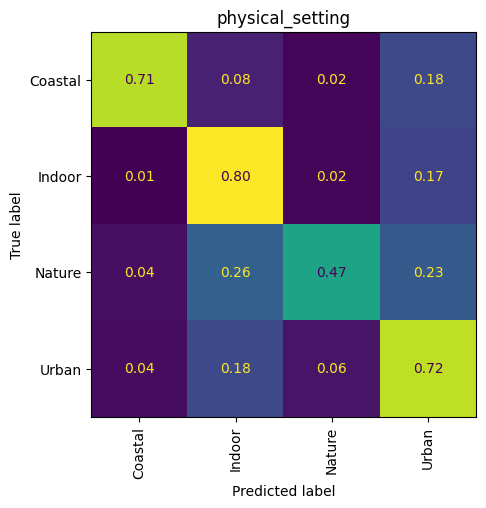

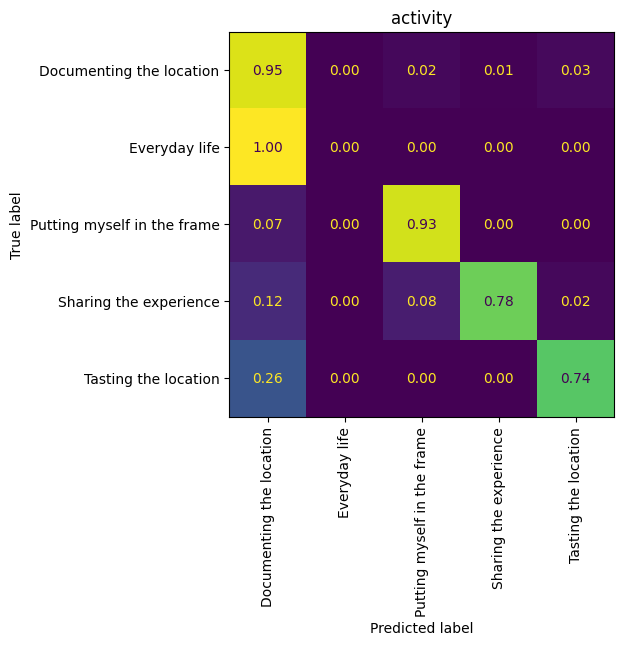

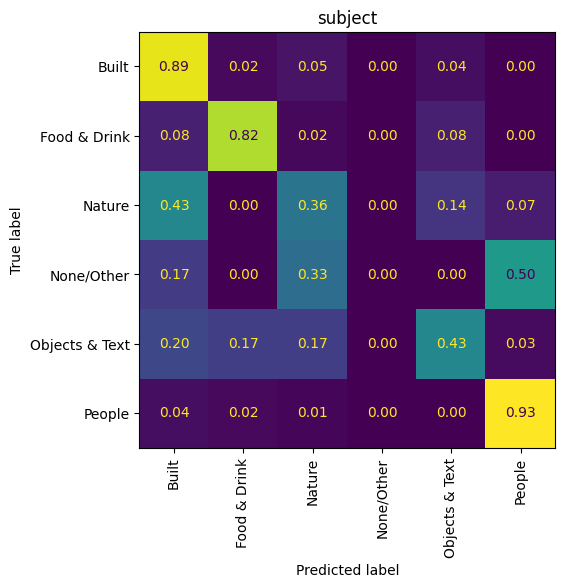

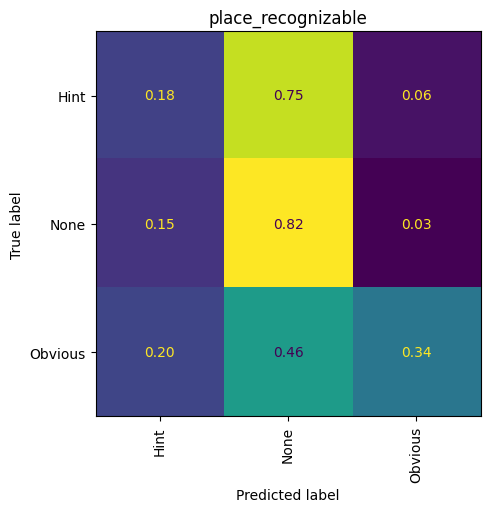

In [15]:
for f in FACETS:
    y, pred, classes = R[f]["y"], R[f]["pred"], R[f]["classes"]
    size = max(5, 0.9 * len(classes))
    fig, ax = plt.subplots(figsize=(size, size))
    ConfusionMatrixDisplay.from_predictions(y, pred, labels=classes, normalize="true", ax=ax,
                                            xticks_rotation="vertical", values_format=".2f", colorbar=False)
    ax.set_title(f)
    plt.show()

The most common confusions as a table, per facet. `A->B (n)` is how many items labeled A were predicted as B; the rate is that as a fraction of A. Compare the two directions to see whether the overlap is asymmetric.

In [16]:
def confusion_pairs(f):
    y, pred, classes = R[f]["y"], R[f]["pred"], R[f]["classes"]
    cm = confusion_matrix(y, pred, labels=classes)
    rows = []
    for i, a in enumerate(classes):
        for j, b_ in enumerate(classes):
            if i < j:
                rows.append({"A": a, "B": b_,
                             "A->B (n)": cm[i, j], "A->B (rate)": cm[i, j] / cm[i].sum(),
                             "B->A (n)": cm[j, i], "B->A (rate)": cm[j, i] / cm[j].sum()})
    pairs = pd.DataFrame(rows)
    pairs["total"] = pairs["A->B (n)"] + pairs["B->A (n)"]
    return pairs.sort_values("total", ascending=False).reset_index(drop=True)

for f in FACETS:
    print("=" * 25, f, "=" * 25)
    R[f]["pairs"] = confusion_pairs(f)
    display(R[f]["pairs"].head(10).round(3))

========================= physical_setting =========================


,A,B,A->B (n),A->B (rate),B->A (n),B->A (rate),total
0,Indoor,Urban,16,0.168,20,0.183,36
1,Nature,Urban,11,0.234,6,0.055,17
2,Indoor,Nature,2,0.021,12,0.255,14
3,Coastal,Urban,9,0.184,4,0.037,13
4,Coastal,Indoor,4,0.082,1,0.011,5
5,Coastal,Nature,1,0.020,2,0.043,3


========================= activity =========================


,A,B,A->B (n),A->B (rate),B->A (n),B->A (rate),total
0,Documenting the location,Tasting the location,4,0.027,13,0.26,17
1,Documenting the location,Everyday life,0,0.000,8,1.00,8
2,Documenting the location,Sharing the experience,1,0.007,6,0.12,7
3,Documenting the location,Putting myself in the frame,3,0.020,3,0.07,6
4,Putting myself in the frame,Sharing the experience,0,0.000,4,0.08,4
5,Sharing the experience,Tasting the location,1,0.020,0,0.00,1
6,Everyday life,Sharing the experience,0,0.000,0,0.00,0
7,Everyday life,Putting myself in the frame,0,0.000,0,0.00,0
8,Everyday life,Tasting the location,0,0.000,0,0.00,0
9,Putting myself in the frame,Tasting the location,0,0.000,0,0.00,0


========================= subject =========================


,A,B,A->B (n),A->B (rate),B->A (n),B->A (rate),total
0,Built,Nature,4,0.048,18,0.429,22
1,Nature,Objects & Text,6,0.143,6,0.171,12
2,Built,Objects & Text,3,0.036,7,0.200,10
3,Food & Drink,Objects & Text,4,0.082,6,0.171,10
4,Built,Food & Drink,2,0.024,4,0.082,6
5,Nature,People,3,0.071,1,0.012,4
6,Built,People,0,0.000,3,0.036,3
7,None/Other,People,3,0.500,0,0.000,3
8,Nature,None/Other,0,0.000,2,0.333,2
9,Food & Drink,People,0,0.000,2,0.024,2


========================= place_recognizable =========================


,A,B,A->B (n),A->B (rate),B->A (n),B->A (rate),total
0,Hint,None,58,0.753,27,0.148,85
1,None,Obvious,5,0.027,19,0.463,24
2,Hint,Obvious,5,0.065,8,0.195,13


Items confused in each direction. By default this shows the most-confused pair of every facet; call `confused(facet, a, b)` with any pair you want to look at.

========================= physical_setting =========================
-- physical_setting: true Indoor -> predicted Urban (16 items)


,filename,label,pred,p_pred,text
77,edinburgh_image9.JPG,Indoor,Urban,0.728,The vaulted Gothic nave of St Giles' Cathedral hung with colorful heraldic banners.
212,madrid_image14.JPG,Indoor,Urban,0.610,Two friends laugh and hug in a cozy brick-walled bar.
291,york_image10.JPG,Indoor,Urban,0.587,Intricately carved stone canopies above the seats in York Minster's Chapter House.
45,cinque_image2.JPG,Indoor,Urban,0.558,A tunnel wall covered in hundreds of hand-painted ceramic tiles.
75,edinburgh_image6.JPG,Indoor,Urban,0.557,"A hand holds open a small book on the Crawford clan's motto, crest, and origins."
187,london_image5.JPG,Indoor,Urban,0.542,"An Indian feast of curries, naan, and rice at the Hichki restaurant."
264,rome_image16.JPG,Indoor,Urban,0.531,A water lily painting in an ornate gold frame hanging on a gallery wall.
196,london_image26.JPG,Indoor,Urban,0.511,A woman lies back in a pink-lit ball pit at an adult ball-pit bar.


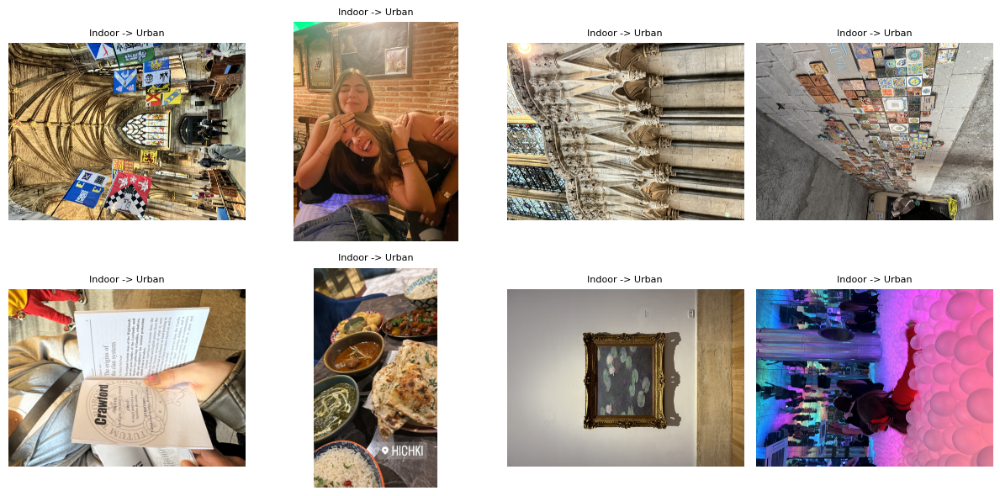

-- physical_setting: true Urban -> predicted Indoor (20 items)


,filename,label,pred,p_pred,text
270,rome_image23.JPG,Urban,Indoor,0.777,Four friends pull silly faces in a selfie in St. Peter's Square.
215,marseille_image8.JPG,Urban,Indoor,0.759,A latte with leaf art in a mint-green cup on a matching green café table.
90,florence_image10.JPG,Urban,Indoor,0.687,"A hand holds two cannoli, pistachio and chocolate chip, in front of a pastry shop window."
66,dublin_image11.JPG,Urban,Indoor,0.637,Colorful painted tiles spelling 'Love Lane' on a wall covered in hearts and handwritten notes.
120,genoa_image7.JPG,Urban,Indoor,0.636,A pale yellow building with painted pink panels and green shutters in Ligurian style.
260,rome_image8.JPG,Urban,Indoor,0.623,Colorful cocktails including spritzes and mojitos with straws on a red tablecloth.
116,genoa_image2.JPG,Urban,Indoor,0.592,White market stalls glowing with warm lights in a city square at twilight.
247,nice_image5.JPG,Urban,Indoor,0.582,A hand holds two bakery bags of pastries and cookies over a sunny pavement.


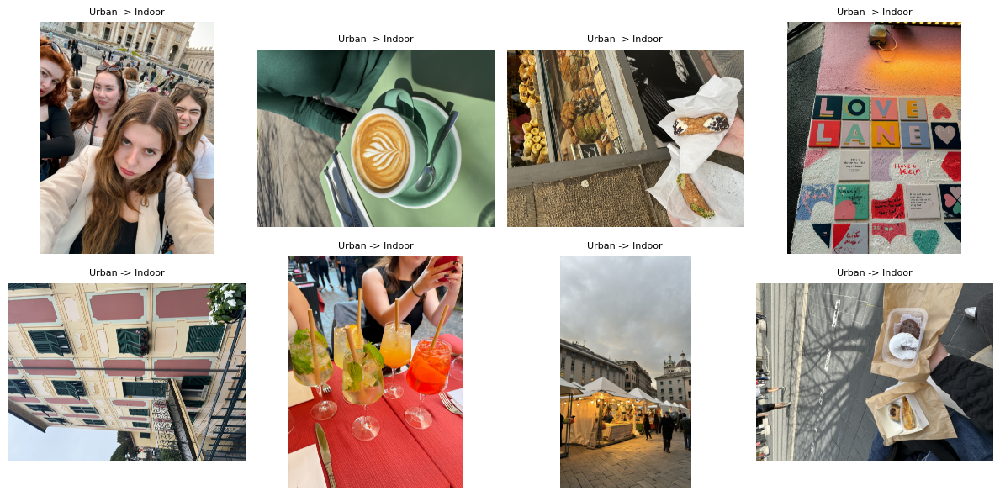

========================= activity =========================
-- activity: true Documenting the location -> predicted Tasting the location (4 items)


,filename,label,pred,p_pred,text
122,genoa_image11.JPG,Documenting the location,Tasting the location,0.840,"A pesto shop counter with a pasta machine, mortars on shelves, and a Pestobene ingredients poster."
75,edinburgh_image6.JPG,Documenting the location,Tasting the location,0.620,"A hand holds open a small book on the Crawford clan's motto, crest, and origins."
249,nice_image7.JPG,Documenting the location,Tasting the location,0.596,A beach restaurant table set with a patterned plate and blue glasses facing the gray sea.
157,leeds_image39.JPG,Documenting the location,Tasting the location,0.504,"A live jazz band with saxophone, keyboard, and drums plays in front of a red curtain."


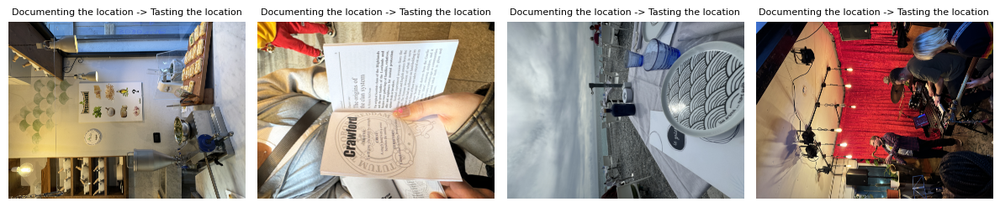

-- activity: true Tasting the location -> predicted Documenting the location (13 items)


,filename,label,pred,p_pred,text
187,london_image5.JPG,Tasting the location,Documenting the location,0.914,"An Indian feast of curries, naan, and rice at the Hichki restaurant."
123,genoa_image12.JPG,Tasting the location,Documenting the location,0.887,Two hands hold small pastries topped with bright green pesto.
93,florence_image14.JPG,Tasting the location,Documenting the location,0.755,Two hands raise an Aperol spritz and a mint spritz in a stone-walled Florentine street.
201,madrid_image3.JPG,Tasting the location,Documenting the location,0.735,"A picnic spread on the grass with baguettes, chips, fruit, cured meats, and drinks."
273,santorini_image3.JPG,Tasting the location,Documenting the location,0.701,Honey-drizzled fried feta with sesame seeds beside a Greek salad and tzatziki.
117,genoa_image3.JPG,Tasting the location,Documenting the location,0.660,A handwritten chalkboard listing wines and spritz prices on a bar wall.
234,morocco_image12.JPG,Tasting the location,Documenting the location,0.611,"A Moroccan lunch of vegetable couscous in a tagine dish, kebabs, fries, and bread."
267,rome_image19.JPG,Tasting the location,Documenting the location,0.505,"Cooking-class workstations set with flour, eggs, rolling pins, and aprons."


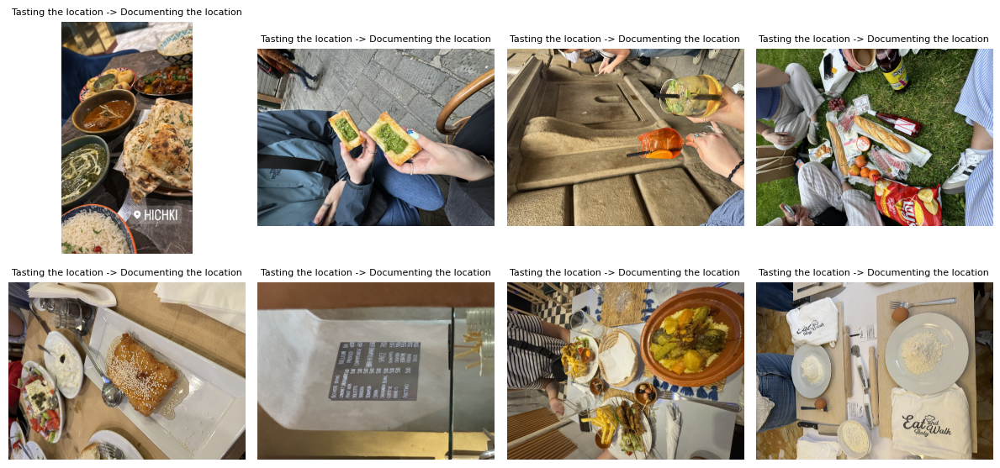

========================= subject =========================
-- subject: true Built -> predicted Nature (4 items)


,filename,label,pred,p_pred,text
72,edinburgh_image1.JPG,Built,Nature,0.841,Edinburgh Castle on its rocky crag seen above green trees under a gray sky.
218,marseille_image16.JPG,Built,Nature,0.583,Panoramic view over Marseille's terracotta rooftops to the surrounding mountains.
32,brussels_image6.JPG,Built,Nature,0.381,The Gothic Brussels Town Hall towering over a busy Grand-Place on a cloudy day.
228,morocco_image1.JPG,Built,Nature,0.328,The earthen ksar of Aït Benhaddou on a hill above a green oasis and dry riverbed.


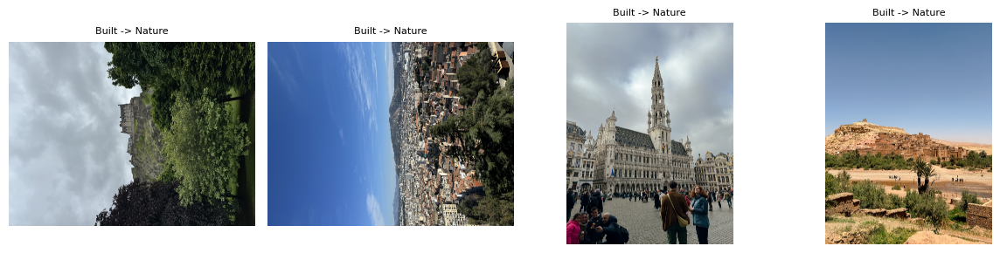

-- subject: true Nature -> predicted Built (18 items)


,filename,label,pred,p_pred,text
253,nice_image13.JPG,Nature,Built,0.862,The sweeping curve of the Baie des Anges and the city of Nice seen from above.
13,amalfi_image21.JPG,Nature,Built,0.782,"Sun breaking through clouds over the sea, seen from high above terraced coastal houses."
255,nice_image15.JPG,Nature,Built,0.764,"View of the Baie des Anges and Nice's red rooftops from Castle Hill, framed by branches."
223,marseille_image26.JPG,Nature,Built,0.751,Looking down a narrow calanque inlet lined with moored sailboats and pine forest.
63,dublin_image7.JPG,Nature,Built,0.742,A grassy garden lawn with a curving path toward colorful buildings under a gray sky.
135,lake_image7.JPG,Nature,Built,0.712,Two people in rain jackets walk down a wet country lane lined with trees.
104,galway_image8.JPG,Nature,Built,0.708,The Cliffs of Moher stretching into the misty Atlantic under an overcast sky.
86,florence_image6.JPG,Nature,Built,0.686,A marble statue atop a fountain in a green garden with trees and bluebells.


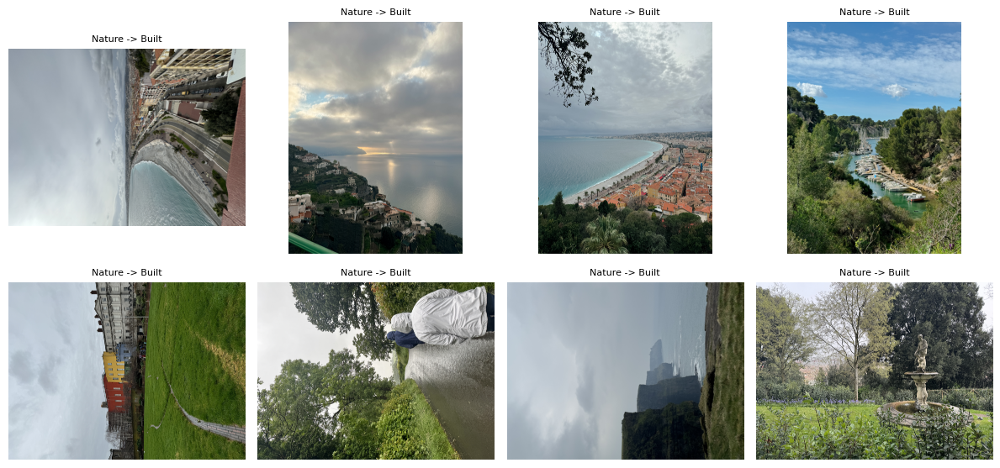

========================= place_recognizable =========================
-- place_recognizable: true Hint -> predicted None (58 items)


,filename,label,pred,p_pred,text
277,santorini_image7.JPG,Hint,None,0.989,Two people walk down a narrow lane between cream-colored walls at dusk.
74,edinburgh_image5.JPG,Hint,None,0.977,Visitors pass through a stone gatehouse between high castle walls at Edinburgh Castle.
266,rome_image18.JPG,Hint,None,0.977,A smiling woman holds up a 'Calendario Romano' calendar of black-and-white priest portraits.
188,london_image7.JPG,Hint,None,0.972,Three friends take a selfie inside a London Eye capsule with the city lit up at night.
238,morocco_image17.JPG,Hint,None,0.971,"A carved, painted pavilion ceiling framing a tiled fountain and garden in Marrakech."
236,morocco_image15.JPG,Hint,None,0.964,"A colorful covered souk lane lined with textiles, bags, and souvenirs under carved wooden screens."
175,liverpool_image1.JPG,Hint,None,0.929,The red wrought-iron Strawberry Field gates set in a stone wall under green trees.
210,madrid_image12.JPG,Hint,None,0.920,A pan of seafood paella with olives and a small cazuela dish on a restaurant table.


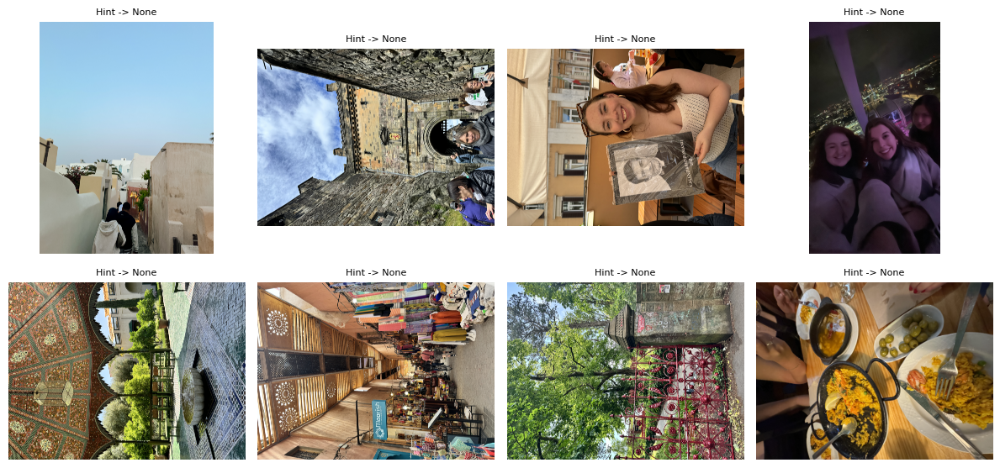

-- place_recognizable: true None -> predicted Hint (27 items)


,filename,label,pred,p_pred,text
218,marseille_image16.JPG,None,Hint,0.857,Panoramic view over Marseille's terracotta rooftops to the surrounding mountains.
103,galway_image7.JPG,None,Hint,0.812,A row of red and pastel terraced houses along a quiet street with parked cars.
197,london_image27.JPG,None,Hint,0.741,A black 'Crawfords Delivery Services' van parked outside a Café de Nata on a London street.
286,york_image2.JPG,None,Hint,0.720,Shoppers walk down a busy street in York lined with old brick buildings and bunting.
214,marseille_image7.JPG,None,Hint,0.691,Two smiling friends take a selfie on the Old Port promenade with Notre-Dame de la Garde in the distance.
99,florence_image24.JPG,None,Hint,0.685,A hand holds up a Kindle e-reader in a garden with bare trees and Tuscan hills behind.
73,edinburgh_image4.JPG,None,Hint,0.675,Crowds in Crown Square at Edinburgh Castle beneath a clock tower and stone buildings.
133,lake_image4.JPG,None,Hint,0.664,A skillet of patatas bravas and a dish of black pudding with bread on a café table.


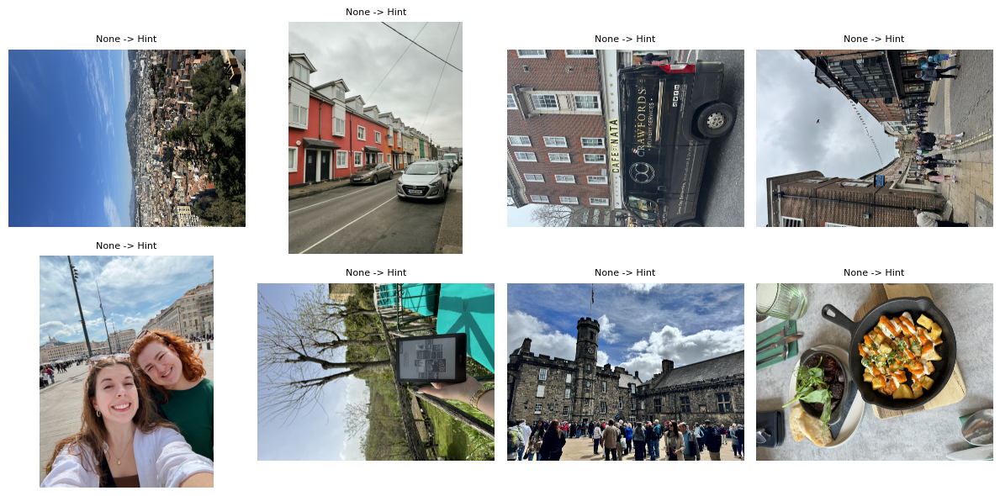

In [17]:
def confused(f, a, b_, k=8):
    '''Items in facet f with true label `a` that the model predicted as `b_`, most confident first.'''
    d = data[f]
    sub = d[(d.label == a) & (d.pred == b_)].sort_values("p_pred", ascending=False).head(k)
    print(f"-- {f}: true {a} -> predicted {b_} ({len(d[(d.label == a) & (d.pred == b_)])} items)")
    display(sub[["filename", "label", "pred", "p_pred", "text"]].round(3))
    show_images(sub, titles=[f"{l} -> {p}" for l, p in zip(sub.label, sub.pred)])

for f in FACETS:
    top = R[f]["pairs"].iloc[0]
    print("=" * 25, f, "=" * 25)
    confused(f, top.A, top.B); confused(f, top.B, top.A)

# e.g. confused("activity", "Documenting the location", "Everyday life")

## Part 5: Which items are most central to each category?
The items with the highest cross-validated probability for their own human label, per facet and class.

=============== physical_setting / Coastal ===============


,filename,label,p_true,text
225,marseille_image29.JPG,Coastal,0.948,"A deep blue calanque opening to the sea, framed by pine trees and white cliffs."
108,galway_image14.JPG,Coastal,0.937,Two people stand on a grassy headland near a sea stack along the Cliffs of Moher.
275,santorini_image5.JPG,Coastal,0.933,A woman in a cap takes a tilted selfie on a white wall above the caldera and cliffside town.
276,santorini_image6.JPG,Coastal,0.933,A smiling woman in a cap stands by a rock with the caldera cliffs and sea behind her.
13,amalfi_image21.JPG,Coastal,0.876,"Sun breaking through clouds over the sea, seen from high above terraced coastal houses."
227,marseille_image32.JPG,Coastal,0.869,Two smiling friends take a selfie on the pebble beach of Calanque d'En-Vau.


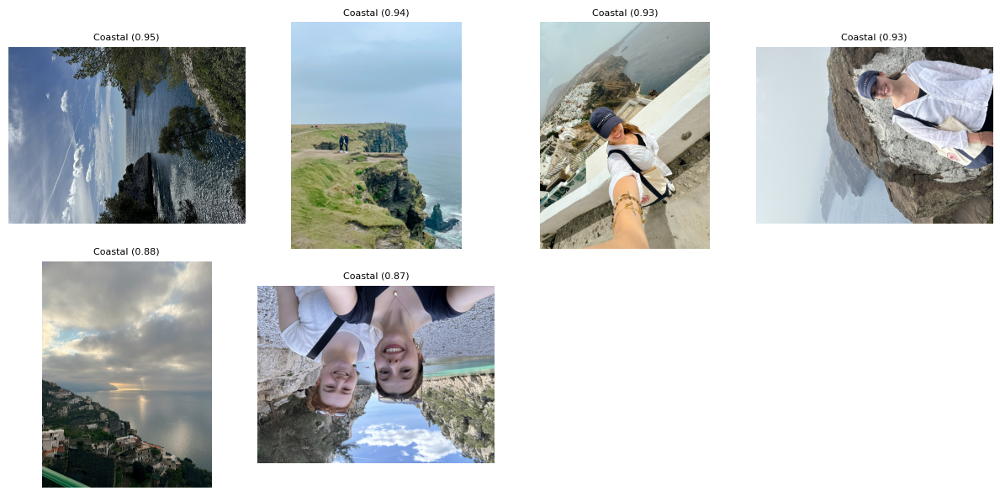

=============== physical_setting / Indoor ===============


,filename,label,p_true,text
37,brussels_image12.JPG,Indoor,0.968,"A sesame-bun burger with fries, ketchup, and a pint of beer on a wooden table."
85,edinburgh_image20.JPG,Indoor,0.968,"A restaurant table with an open menu, red wine glasses, and a carafe of water."
17,barcelona_image7.JPG,Indoor,0.968,"Three rustic bowls of salads and grain bowls, one with sliced steak and sourdough, on a wooden table."
35,brussels_image10.JPG,Indoor,0.968,A long flight of colorful beer tasters on a graffiti-carved round wooden table.
61,dublin_image5.JPG,Indoor,0.953,A pint of Guinness on a polished wooden pub table.
6,amalfi_image12.JPG,Indoor,0.949,"Inside a colorful boutique full of hanging wicker lamps, patchwork bags, and textiles."


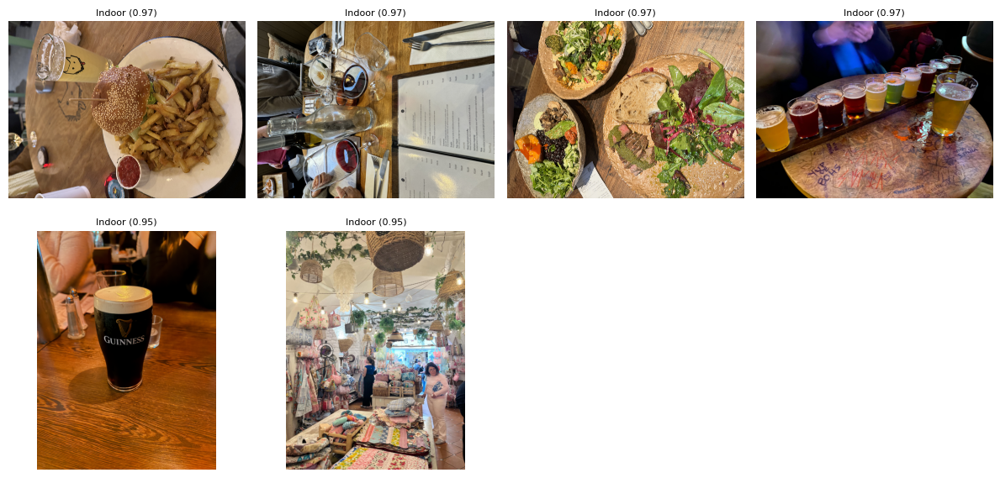

=============== physical_setting / Nature ===============


,filename,label,p_true,text
203,madrid_image5.JPG,Nature,0.969,Rose-covered arches over a curving path in the Rosaleda rose garden of Retiro Park.
86,florence_image6.JPG,Nature,0.906,A marble statue atop a fountain in a green garden with trees and bluebells.
207,madrid_image9.JPG,Nature,0.862,Four friends pose on a path in the Retiro rose garden surrounded by pink blooms.
230,morocco_image5.JPG,Nature,0.781,A smiling woman in a patterned headscarf takes a tilted selfie on a camel in the desert.
229,morocco_image3.JPG,Nature,0.739,A smiling woman in black stands on a rocky desert track with barren hills behind.
136,lake_image8.JPG,Nature,0.717,A green meadow with a small pond and trees under a bright blue sky with puffy clouds.


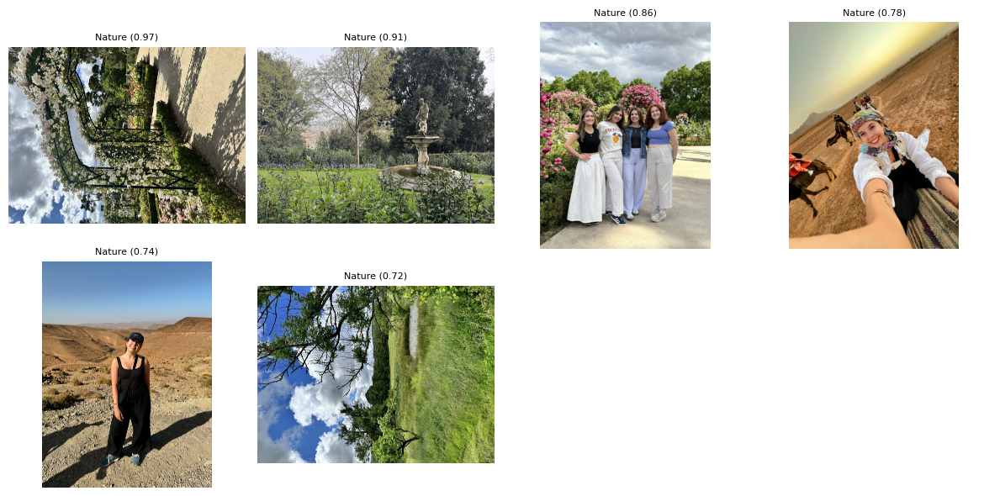

=============== physical_setting / Urban ===============


,filename,label,p_true,text
126,genoa_image16.JPG,Urban,0.989,A long city street lined with tall buildings and café umbrellas leading to a domed church.
286,york_image2.JPG,Urban,0.980,Shoppers walk down a busy street in York lined with old brick buildings and bunting.
79,edinburgh_image12.JPG,Urban,0.979,Tall old stone tenements tower over a busy cobbled street in Edinburgh's Old Town.
178,liverpool_image4.JPG,Urban,0.967,A 'Penny Lane' street sign on the corner of a red-brick building with parked cars along the road.
243,nice_image1.JPG,Urban,0.954,A smiling woman stands in front of a boutique called 'Nat's' on a hexagon-paved street.
171,lisbon_image18.JPG,Urban,0.954,Friends walk up a narrow street lined with pastel pink and yellow buildings.


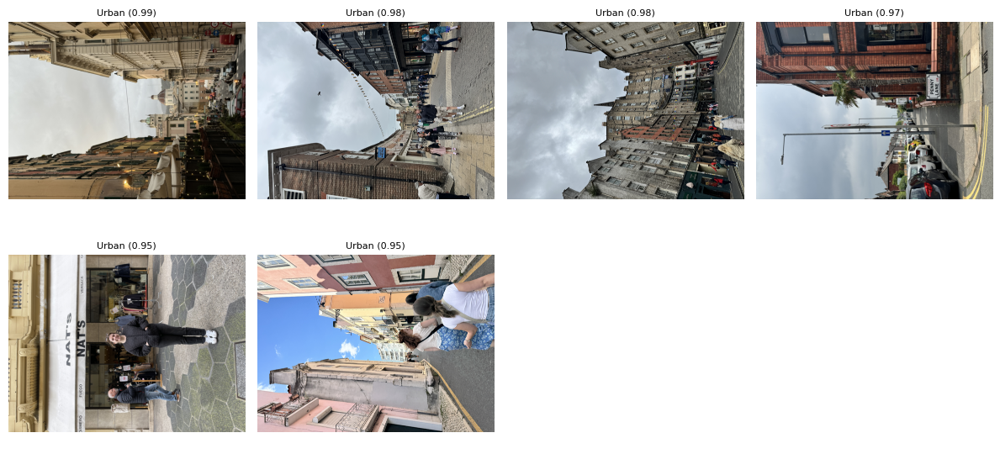

=============== activity / Documenting the location ===============


,filename,label,p_true,text
55,cinque_image17.JPG,Documenting the location,0.995,Looking down a busy street of colorful buildings toward the sea under a hazy sun.
13,amalfi_image21.JPG,Documenting the location,0.990,"Sun breaking through clouds over the sea, seen from high above terraced coastal houses."
225,marseille_image29.JPG,Documenting the location,0.986,"A deep blue calanque opening to the sea, framed by pine trees and white cliffs."
23,barcelona_image16.JPG,Documenting the location,0.986,Looking up at the white trencadís ceiling and mosaic medallions above the columns of Park Güell's Hypostyle Room.
7,amalfi_image13.JPG,Documenting the location,0.985,"A steep, narrow stone staircase climbs between whitewashed walls toward a blue sky."
287,york_image4.JPG,Documenting the location,0.985,Crowds pack the narrow Shambles beneath hanging signs for the Shambles Kitchen and food court.


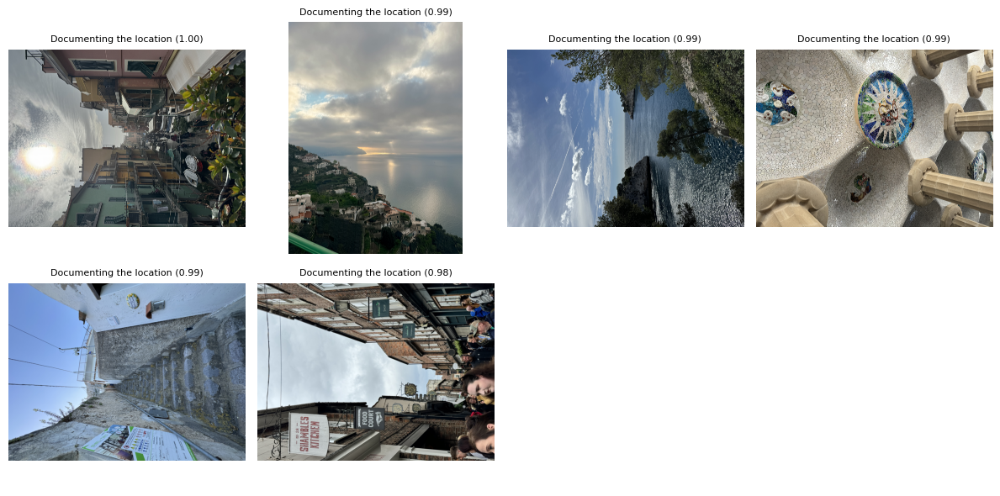

=============== activity / Everyday life ===============


,filename,label,p_true,text
145,leeds_image9.JPG,Everyday life,0.165,View from the back of a wood-paneled lecture theater with a tablet of notes in the foreground.
116,genoa_image2.JPG,Everyday life,0.055,White market stalls glowing with warm lights in a city square at twilight.
296,york_image15.JPG,Everyday life,0.054,A hand holds a small white crocheted ghost toy in the back seat of a car.
99,florence_image24.JPG,Everyday life,0.049,A hand holds up a Kindle e-reader in a garden with bare trees and Tuscan hills behind.
297,york_image16.JPG,Everyday life,0.028,A cozy guesthouse bedroom with twin beds under low black-beamed ceilings.
252,nice_image11.JPG,Everyday life,0.025,Shoppers browse market stalls under striped awnings in Nice's Cours Saleya.


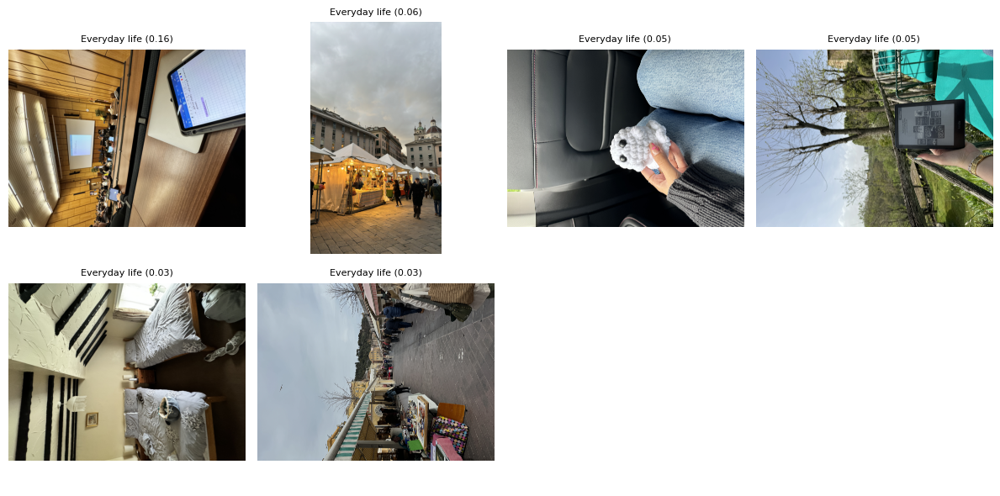

=============== activity / Putting myself in the frame ===============


,filename,label,p_true,text
46,cinque_image3.JPG,Putting myself in the frame,0.957,A smiling woman with a blue sweater over her shoulders sits on a green bench in the sun.
20,barcelona_image12.JPG,Putting myself in the frame,0.949,A woman sits on the mosaic bench at Park Güell with the gatehouse tower and city behind her.
138,lake_image11.JPG,Putting myself in the frame,0.937,A smiling woman in a black sweater stands on a rocky viewpoint above Lake Windermere.
283,santorini_image17.JPG,Putting myself in the frame,0.936,A smiling woman in a red dress takes a fisheye selfie on a white wall above the caldera.
231,morocco_image7.JPG,Putting myself in the frame,0.936,A woman in a blue sweater stands on rocky ground as the sun rises behind the hills.
276,santorini_image6.JPG,Putting myself in the frame,0.935,A smiling woman in a cap stands by a rock with the caldera cliffs and sea behind her.


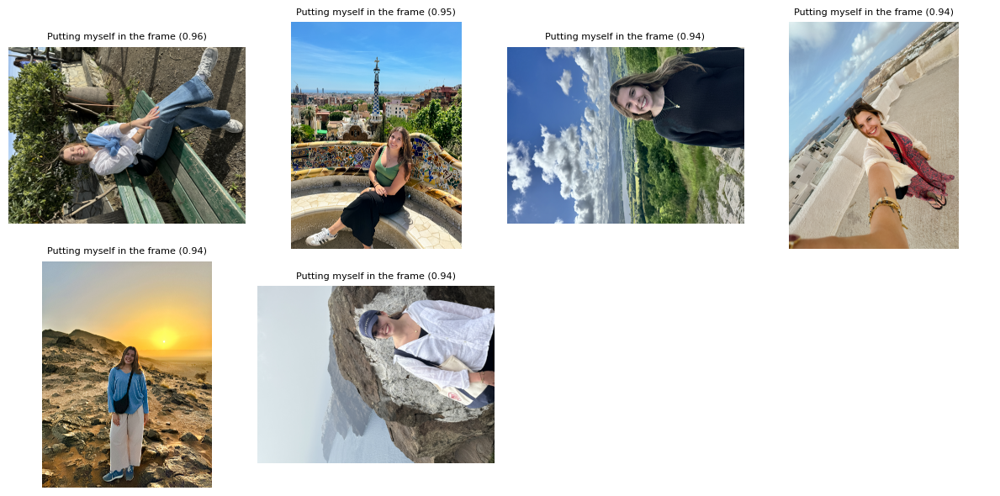

=============== activity / Sharing the experience ===============


,filename,label,p_true,text
221,marseille_image21.JPG,Sharing the experience,0.981,Two friends in sunglasses take a selfie in front of Palais Longchamp.
147,leeds_image12.JPG,Sharing the experience,0.980,A dim late-night selfie of two friends lying in bed making faces.
102,galway_image5.JPG,Sharing the experience,0.976,Three friends in winter jackets pose on a windy seaside promenade.
227,marseille_image32.JPG,Sharing the experience,0.970,Two smiling friends take a selfie on the pebble beach of Calanque d'En-Vau.
217,marseille_image15.JPG,Sharing the experience,0.965,Two friends pose at a hilltop viewpoint with the sea and coastline behind them.
205,madrid_image7.JPG,Sharing the experience,0.964,Two friends pose in front of climbing pink roses in a sunny rose garden.


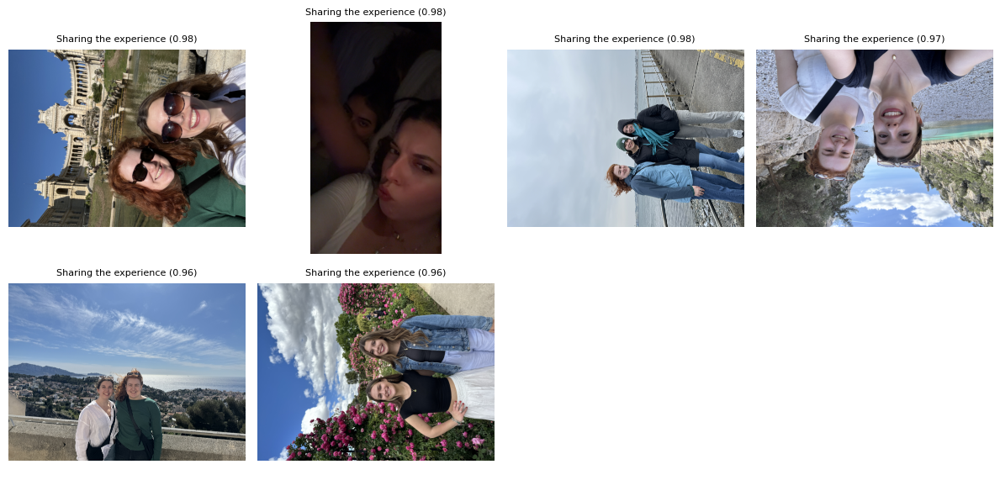

=============== activity / Tasting the location ===============


,filename,label,p_true,text
3,amalfi_image7.JPG,Tasting the location,0.977,A glass of white spritz with mint and a straw on a patterned café table.
257,rome_image2.JPG,Tasting the location,0.976,"Glasses of spritz, white wine, and red wine on a restaurant table with red napkins."
210,madrid_image12.JPG,Tasting the location,0.968,A pan of seafood paella with olives and a small cazuela dish on a restaurant table.
85,edinburgh_image20.JPG,Tasting the location,0.965,"A restaurant table with an open menu, red wine glasses, and a carafe of water."
17,barcelona_image7.JPG,Tasting the location,0.962,"Three rustic bowls of salads and grain bowls, one with sliced steak and sourdough, on a wooden table."
37,brussels_image12.JPG,Tasting the location,0.952,"A sesame-bun burger with fries, ketchup, and a pint of beer on a wooden table."


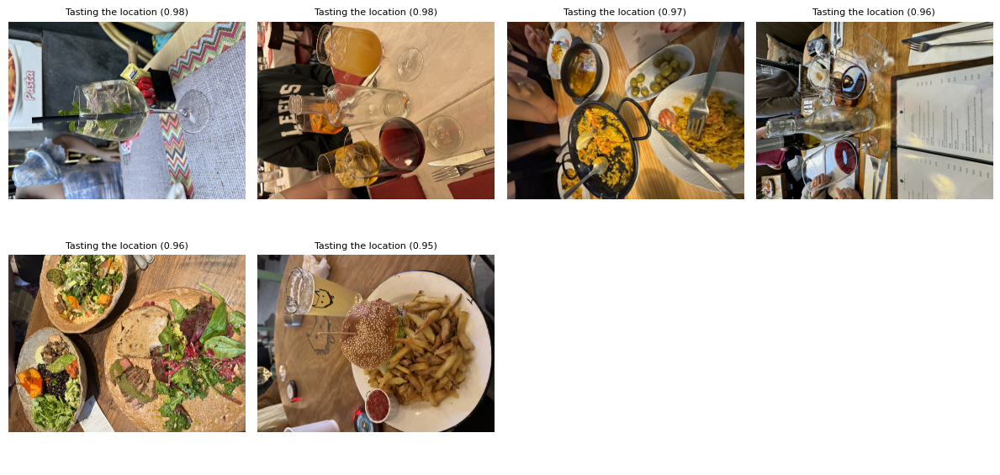

=============== subject / Built ===============


,filename,label,p_true,text
286,york_image2.JPG,Built,0.996,Shoppers walk down a busy street in York lined with old brick buildings and bunting.
83,edinburgh_image18.JPG,Built,0.982,The Water of Leith flowing past the old stone buildings of Dean Village.
27,barcelona_image24.JPG,Built,0.969,Looking up the nave of the Sagrada Família at its tree-like columns and starburst ceiling.
289,york_image6.JPG,Built,0.968,"The high altar and carved stone choir screen in York Minster's nave, with the organ above."
294,york_image13.JPG,Built,0.955,"The towers of York Minster rising above brick buildings, seen from the city walls."
171,lisbon_image18.JPG,Built,0.942,Friends walk up a narrow street lined with pastel pink and yellow buildings.


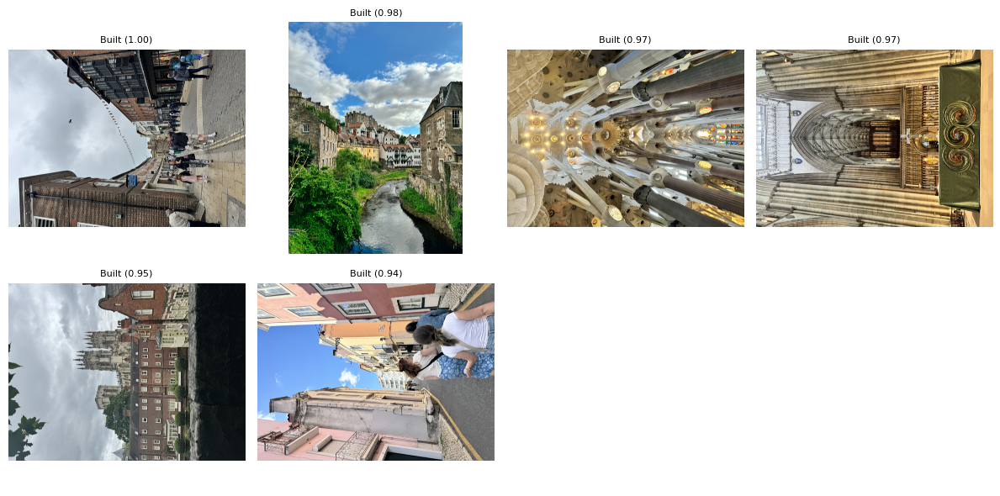

=============== subject / Food & Drink ===============


,filename,label,p_true,text
37,brussels_image12.JPG,Food & Drink,0.974,"A sesame-bun burger with fries, ketchup, and a pint of beer on a wooden table."
3,amalfi_image7.JPG,Food & Drink,0.965,A glass of white spritz with mint and a straw on a patterned café table.
257,rome_image2.JPG,Food & Drink,0.955,"Glasses of spritz, white wine, and red wine on a restaurant table with red napkins."
172,lisbon_image21.JPG,Food & Drink,0.953,"Bowls of noodles, shrimp, and a dipping broth with fresh vegetables on a marble table."
17,barcelona_image7.JPG,Food & Drink,0.951,"Three rustic bowls of salads and grain bowls, one with sliced steak and sourdough, on a wooden table."
210,madrid_image12.JPG,Food & Drink,0.950,A pan of seafood paella with olives and a small cazuela dish on a restaurant table.


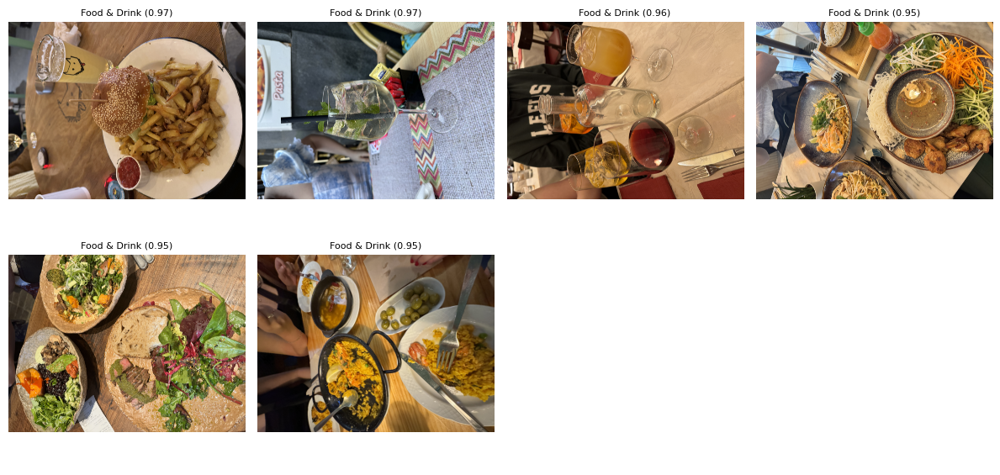

=============== subject / Nature ===============


,filename,label,p_true,text
4,amalfi_image8.JPG,Nature,0.804,"Point-of-view shot of legs on a dark sand beach looking out at the sea under a bright, hazy sun."
108,galway_image14.JPG,Nature,0.783,Two people stand on a grassy headland near a sea stack along the Cliffs of Moher.
225,marseille_image29.JPG,Nature,0.750,"A deep blue calanque opening to the sea, framed by pine trees and white cliffs."
136,lake_image8.JPG,Nature,0.715,A green meadow with a small pond and trees under a bright blue sky with puffy clouds.
254,nice_image14.JPG,Nature,0.611,The cascading waterfall on Castle Hill in Nice falling into a pool.
248,nice_image6.JPG,Nature,0.600,A pebbly beach in Nice with turquoise waves and Castle Hill in the background.


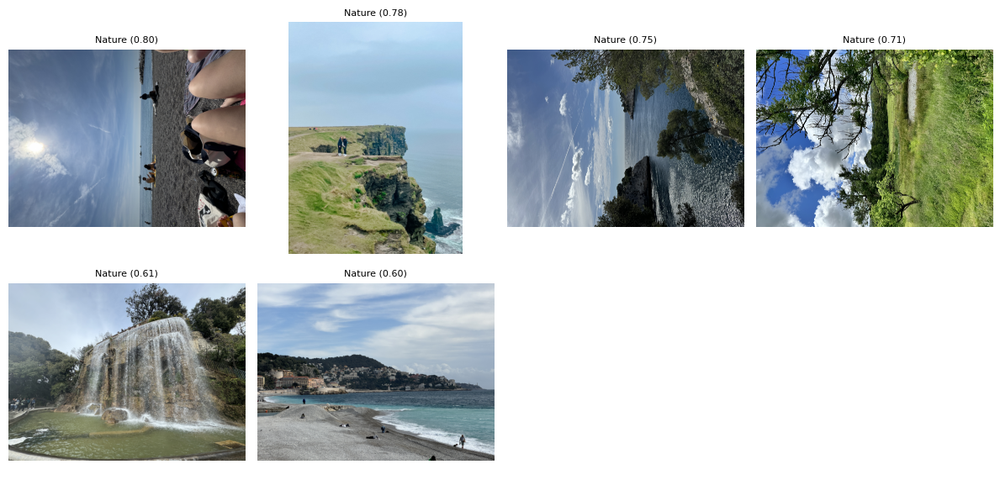

=============== subject / None/Other ===============


,filename,label,p_true,text
196,london_image26.JPG,None/Other,0.077,A woman lies back in a pink-lit ball pit at an adult ball-pit bar.
189,london_image9.JPG,None/Other,0.058,"A woman shoots hoops at an arcade basketball game in a dim, blue-lit room."
252,nice_image11.JPG,None/Other,0.054,Shoppers browse market stalls under striped awnings in Nice's Cours Saleya.
285,santorini_image19.JPG,None/Other,0.029,"Neon lights, lasers, and a disco ball over a packed crowd in a nightclub."
297,york_image16.JPG,None/Other,0.024,A cozy guesthouse bedroom with twin beds under low black-beamed ceilings.
5,amalfi_image10.JPG,None/Other,0.014,View from inside a crowded bus as it passes another SITA bus on a narrow coastal road.


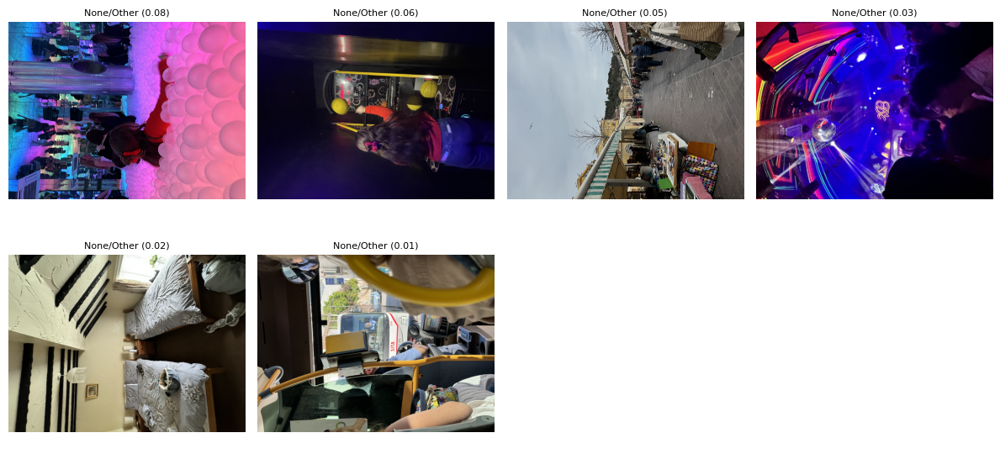

=============== subject / Objects & Text ===============


,filename,label,p_true,text
76,edinburgh_image7.JPG,Objects & Text,0.872,A 'Royal Mile' street sign on a sandstone building beside a Witchery Tour plaque.
96,florence_image21.JPG,Objects & Text,0.843,A pink neon 'Vivoli' sign glowing on a dark wall at night.
179,liverpool_image5.JPG,Objects & Text,0.829,"A weathered, graffiti-covered 'Penny Lane' sign behind protective glass on a stone wall."
264,rome_image16.JPG,Objects & Text,0.689,A water lily painting in an ornate gold frame hanging on a gallery wall.
130,lake_image1.JPG,Objects & Text,0.628,"A 'Welcome to Crawford, Please Drive Carefully' village sign on a grassy roadside."
66,dublin_image11.JPG,Objects & Text,0.609,Colorful painted tiles spelling 'Love Lane' on a wall covered in hearts and handwritten notes.


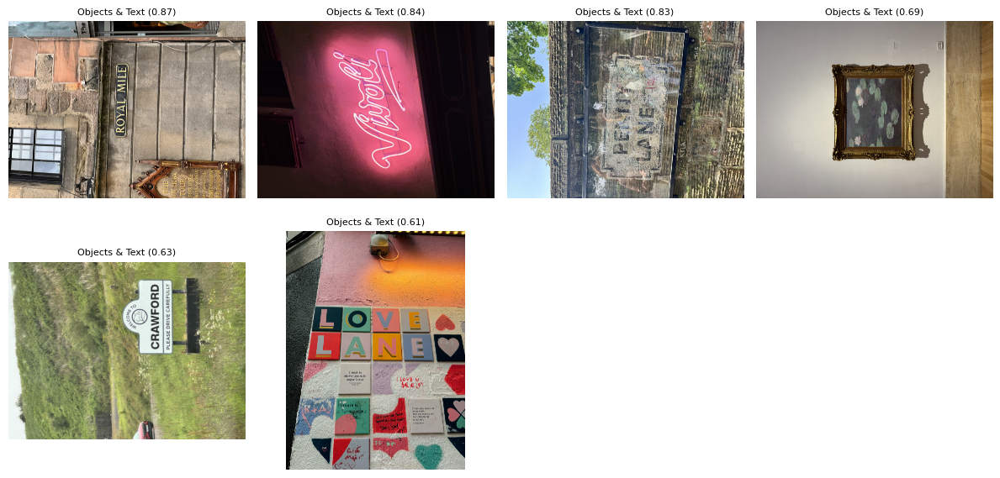

=============== subject / People ===============


,filename,label,p_true,text
109,galway_image15.JPG,People,0.995,A smiling selfie of a woman in a bike helmet with two friends on a country road.
160,lisbon_image1.JPG,People,0.987,Four smiling friends take a selfie in front of a wall of colorful artificial flowers.
230,morocco_image5.JPG,People,0.981,A smiling woman in a patterned headscarf takes a tilted selfie on a camel in the desert.
67,dublin_image13.JPG,People,0.979,A smiling woman holding a black umbrella stands in the cobbled courtyard of Dublin Castle.
265,rome_image17.JPG,People,0.976,A smiling woman poses in front of the Trevi Fountain.
214,marseille_image7.JPG,People,0.976,Two smiling friends take a selfie on the Old Port promenade with Notre-Dame de la Garde in the distance.


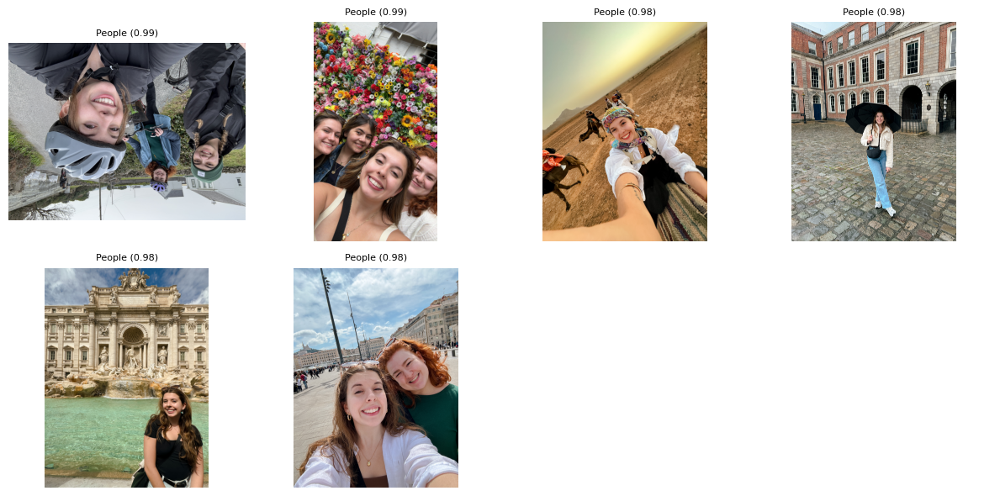

=============== place_recognizable / Hint ===============


,filename,label,p_true,text
241,morocco_image24.JPG,Hint,0.879,Point-of-view from a camel saddle following a line of riders across the desert.
81,edinburgh_image15.JPG,Hint,0.856,"View from Arthur's Seat over green hills, the city, and the Firth of Forth."
178,liverpool_image4.JPG,Hint,0.790,A 'Penny Lane' street sign on the corner of a red-brick building with parked cars along the road.
75,edinburgh_image6.JPG,Hint,0.762,"A hand holds open a small book on the Crawford clan's motto, crest, and origins."
255,nice_image15.JPG,Hint,0.658,"View of the Baie des Anges and Nice's red rooftops from Castle Hill, framed by branches."
76,edinburgh_image7.JPG,Hint,0.602,A 'Royal Mile' street sign on a sandstone building beside a Witchery Tour plaque.


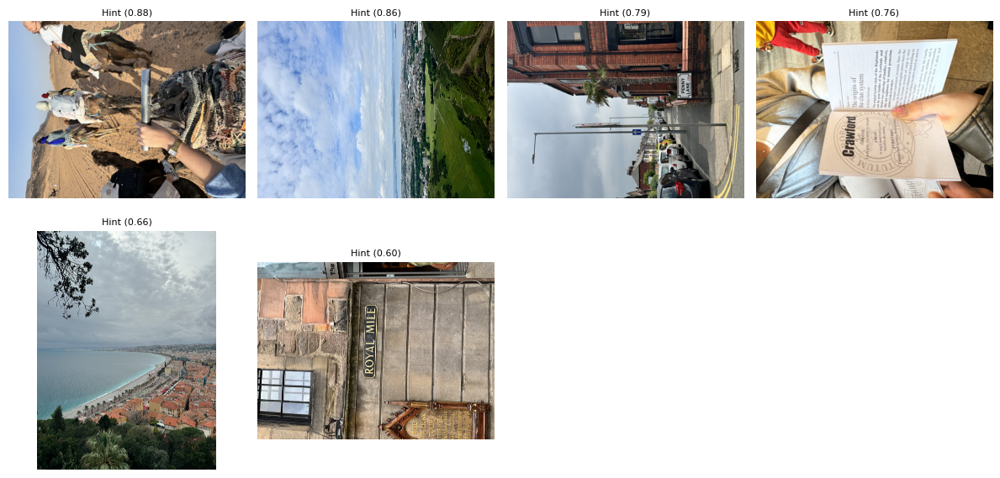

=============== place_recognizable / None ===============


,filename,label,p_true,text
205,madrid_image7.JPG,None,0.992,Two friends pose in front of climbing pink roses in a sunny rose garden.
204,madrid_image6.JPG,None,0.992,A smiling woman in a denim jacket stands among blooming pink roses in a garden.
98,florence_image23.JPG,None,0.991,A woman takes a mirror selfie in an immersive art room projected with giant flowers.
135,lake_image7.JPG,None,0.987,Two people in rain jackets walk down a wet country lane lined with trees.
206,madrid_image8.JPG,None,0.984,Three friends stand together in a rose garden under a blue sky with puffy clouds.
143,lake_image21.JPG,None,0.984,"A pink-walled room in a historic house with an oil painting, large Imari vases, and a wooden chest."


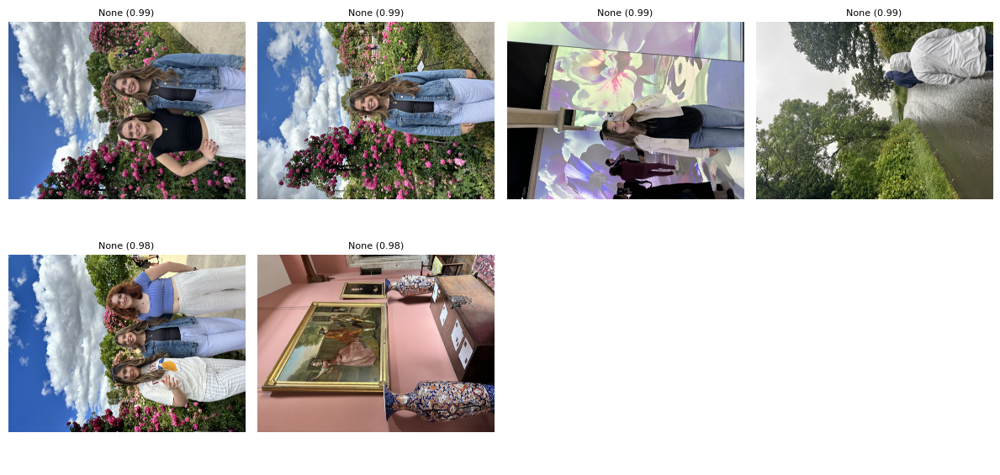

=============== place_recognizable / Obvious ===============


,filename,label,p_true,text
30,brussels_image1.JPG,Obvious,0.876,A woman in a teal scarf stands in the Grand-Place with the Gothic Town Hall tower behind her.
106,galway_image12.JPG,Obvious,0.870,A woman in a teal scarf stands on a clifftop with the Cliffs of Moher behind her.
190,london_image12.JPG,Obvious,0.727,A woman in a long coat walks on the sidewalk with Big Ben behind her.
276,santorini_image6.JPG,Obvious,0.682,A smiling woman in a cap stands by a rock with the caldera cliffs and sea behind her.
44,cinque_image1.JPG,Obvious,0.675,The colorful cliffside village of Manarola above crashing waves in Cinque Terre.
33,brussels_image7.JPG,Obvious,0.627,Three friends in scarves pose in the Grand-Place in front of the Town Hall.


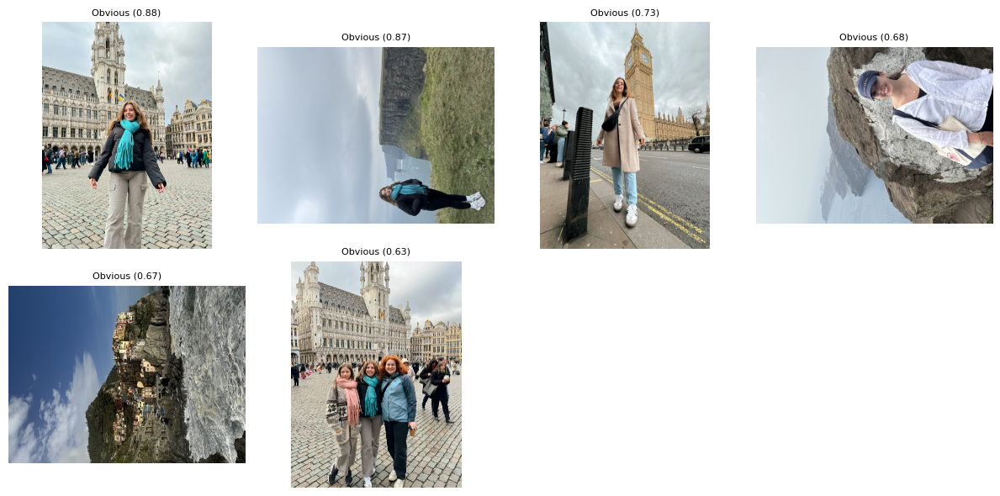

In [18]:
K_CENTRAL = 6
FACETS_TO_SHOW = None     # e.g. ["subject"]; None = all

def central_items(f, label, k=K_CENTRAL):
    d = data[f]
    return d[d.label == label].sort_values("p_true", ascending=False).head(k)

for f in (FACETS_TO_SHOW or FACETS):
    for c in R[f]["classes"]:
        print("=" * 15, f, "/", c, "=" * 15)
        sub = central_items(f, c)
        display(sub[["filename", "label", "p_true", "text"]].round(3))
        show_images(sub, titles=[f"{l} ({p:.2f})" for l, p in zip(sub.label, sub.p_true)])

## Part 6: Which items is the model most uncertain about?

Margin = top probability minus second probability (small = uncertain). `n_known` is how many of the model's vocabulary words occur in the caption; items with very few known words are uncertain only because the model has nothing to go on.

========================= physical_setting =========================


,filename,label,top1,top2,margin,n_known,text
256,nice_image18.JPG,Coastal,Indoor,Urban,0.000,11,A woman poses at a wall overlooking Monaco's harbor and high-rises.
148,leeds_image14.jpg,Nature,Urban,Indoor,0.001,11,A woman in sunglasses and a leopard skirt poses in a festival crowd in front of a large stage.
29,barcelona_image27.JPG,Indoor,Indoor,Urban,0.006,10,"Two colorful poke-style bowls with steak, pickled onions, and greens, plus a pink juice."
117,genoa_image3.JPG,Indoor,Urban,Indoor,0.006,10,A handwritten chalkboard listing wines and spritz prices on a bar wall.
299,york_image18.JPG,Indoor,Nature,Urban,0.007,10,"The Lion Inn, a stone country pub, seen through the rear window of a car."
285,santorini_image19.JPG,Indoor,Indoor,Nature,0.009,8,"Neon lights, lasers, and a disco ball over a packed crowd in a nightclub."
219,marseille_image17.JPG,Urban,Nature,Urban,0.012,16,Notre-Dame de la Garde basilica on its hill above trees and a street of parked cars.
23,barcelona_image16.JPG,Indoor,Coastal,Indoor,0.013,15,Looking up at the white trencadís ceiling and mosaic medallions above the columns of Park Güell's Hypostyle Room.
113,galway_image23.JPG,Coastal,Coastal,Urban,0.015,12,Three friends stand together on flat limestone rocks with the sea behind them.
183,liverpool_image9.JPG,Urban,Indoor,Urban,0.018,7,Giant colorful letters spelling 'LIVERPOOL' along a paved waterfront walkway.


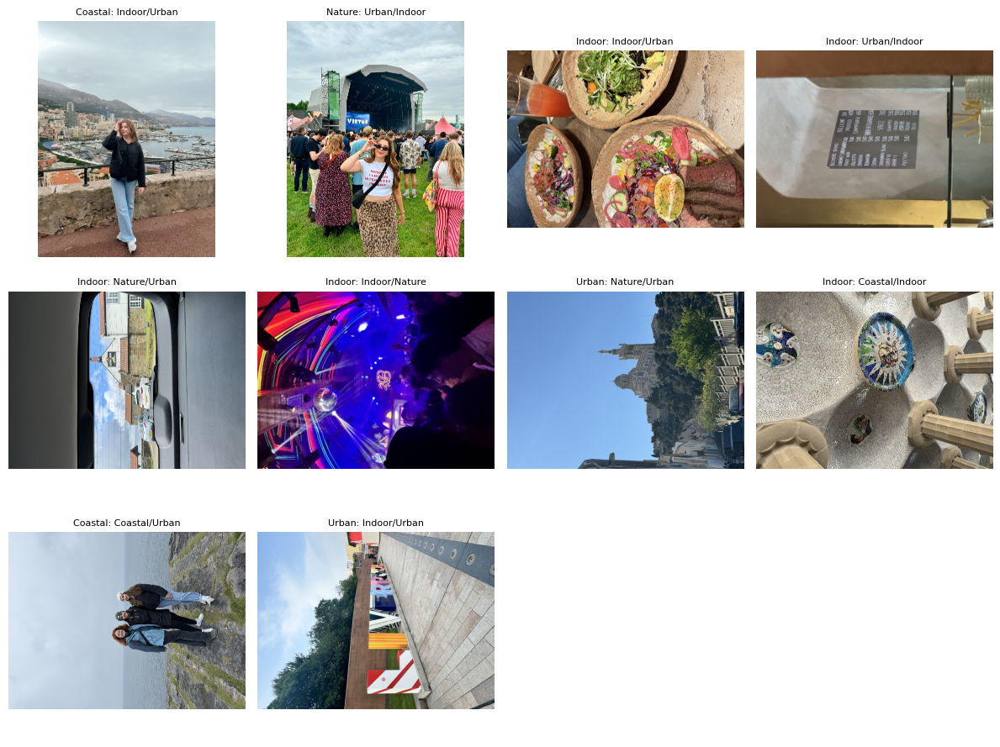

========================= activity =========================


,filename,label,top1,top2,margin,n_known,text
1,amalfi_image5.JPG,Tasting the location,Documenting the location,Everyday life,0.002,10,"A hand holds lemon sorbet served in a hollowed-out lemon with a leaf, inside a gelato shop."
134,lake_image5.JPG,Tasting the location,Documenting the location,Tasting the location,0.009,7,Chocolate crêpes with raspberries and hazelnuts and a brownie with ice cream in speckled bowls.
88,florence_image8.JPG,Documenting the location,Putting myself in the frame,Documenting the location,0.015,13,A woman with curly hair walks down a narrow Florentine street past a small yellow car.
216,marseille_image11.JPG,Putting myself in the frame,Documenting the location,Putting myself in the frame,0.020,10,A smiling woman in a white shirt walks down a sunny sloping residential street.
271,rome_image26.JPG,Sharing the experience,Tasting the location,Documenting the location,0.024,9,Women in aprons whisk eggs and mascarpone while making tiramisu in a cooking class.
145,leeds_image9.JPG,Everyday life,Documenting the location,Sharing the experience,0.034,11,View from the back of a wood-paneled lecture theater with a tablet of notes in the foreground.
260,rome_image8.JPG,Tasting the location,Tasting the location,Documenting the location,0.038,9,Colorful cocktails including spritzes and mojitos with straws on a red tablecloth.
168,lisbon_image13.jpg,Putting myself in the frame,Documenting the location,Putting myself in the frame,0.041,10,A woman waves beside a railing under a jacaranda tree at a Lisbon miradouro.
143,lake_image21.JPG,Documenting the location,Documenting the location,Tasting the location,0.046,12,"A pink-walled room in a historic house with an oil painting, large Imari vases, and a wooden chest."
268,rome_image20.JPG,Tasting the location,Documenting the location,Tasting the location,0.067,9,A hand holds up a cup of homemade tiramisu during a cooking class.


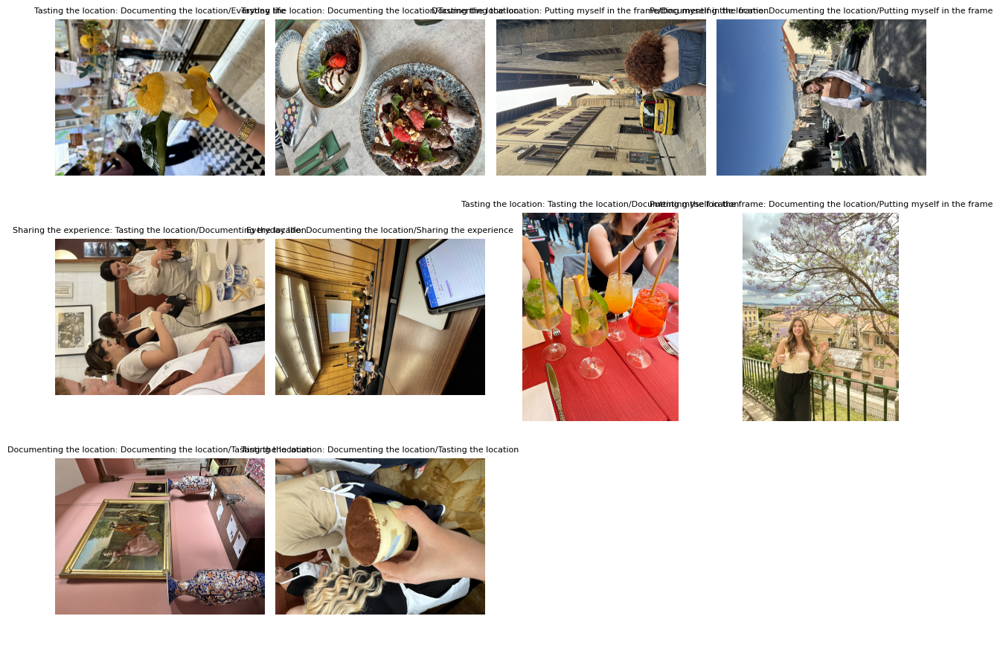

========================= subject =========================


,filename,label,top1,top2,margin,n_known,text
234,morocco_image12.JPG,Food & Drink,Built,Food & Drink,0.005,9,"A Moroccan lunch of vegetable couscous in a tagine dish, kebabs, fries, and bread."
201,madrid_image3.JPG,Food & Drink,Built,Nature,0.008,6,"A picnic spread on the grass with baguettes, chips, fruit, cured meats, and drinks."
180,liverpool_image6.JPG,Objects & Text,Objects & Text,Built,0.010,8,Museum display cases showing 'Love Me Do' vinyl records in a red Beatles exhibit.
142,lake_image20.JPG,Nature,Built,Nature,0.012,13,A herd of black-and-white cows gathers at a metal farm gate under a pink sunset sky.
95,florence_image18.JPG,Built,Built,Objects & Text,0.013,4,The flower-garlanded arched entrance of the Officina Profumo-Farmaceutica di Santa Maria Novella.
203,madrid_image5.JPG,Nature,People,Nature,0.015,13,Rose-covered arches over a curving path in the Rosaleda rose garden of Retiro Park.
181,liverpool_image7.JPG,Objects & Text,Objects & Text,Food & Drink,0.016,10,"A replica Cavern Club stage with Beatles-branded drums, guitars, and a colorful band-name wall."
296,york_image15.JPG,Objects & Text,Built,Objects & Text,0.021,12,A hand holds a small white crocheted ghost toy in the back seat of a car.
267,rome_image19.JPG,Food & Drink,Built,Food & Drink,0.022,7,"Cooking-class workstations set with flour, eggs, rolling pins, and aprons."
141,lake_image19.JPG,Nature,Objects & Text,People,0.023,11,Two curious black-and-white cows up close in a pasture at sunset.


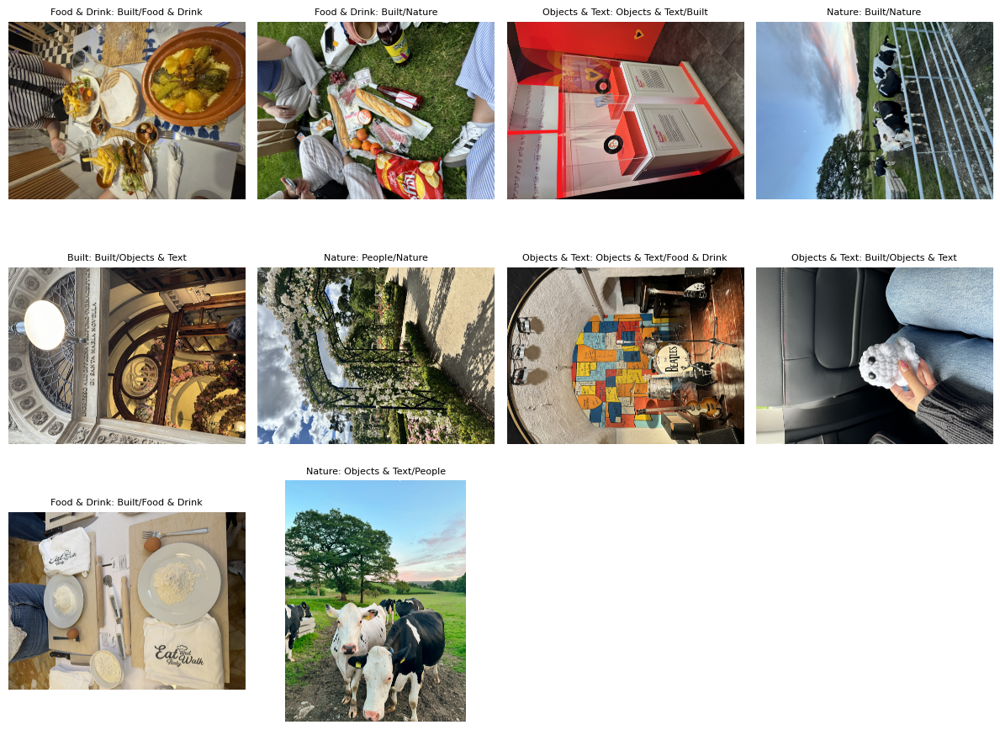

========================= place_recognizable =========================


,filename,label,top1,top2,margin,n_known,text
83,edinburgh_image18.JPG,Hint,Hint,None,0.001,8,The Water of Leith flowing past the old stone buildings of Dean Village.
233,morocco_image11.JPG,None,Hint,None,0.004,12,Looking down into the tiled courtyard of a traditional riad with carved balconies and rugs.
283,santorini_image17.JPG,None,Obvious,None,0.005,13,A smiling woman in a red dress takes a fisheye selfie on a white wall above the caldera.
242,morocco_image25.JPG,None,None,Hint,0.005,8,A lush palm oasis stretches toward a rocky mountain under a hazy sky.
174,lisbon_image23.JPG,None,None,Hint,0.006,11,A woman stands in front of a colorful street-art mural of cartoon faces.
258,rome_image5.JPG,Obvious,None,Hint,0.010,6,The ruins of the Roman Forum with churches and the Vittoriano monument behind.
232,morocco_image8.JPG,Hint,None,Hint,0.012,10,"A saddled camel kneels on the sand looking at the camera, with a caravan behind in the haze."
251,nice_image10.JPG,None,None,Hint,0.017,12,A woman walks along the Promenade des Anglais past blue chairs and a white pergola.
79,edinburgh_image12.JPG,Hint,Hint,None,0.021,11,Tall old stone tenements tower over a busy cobbled street in Edinburgh's Old Town.
292,york_image11.JPG,None,None,Hint,0.022,9,"Pedestrians pass under Bootham Bar, a medieval stone gate in York's city walls."


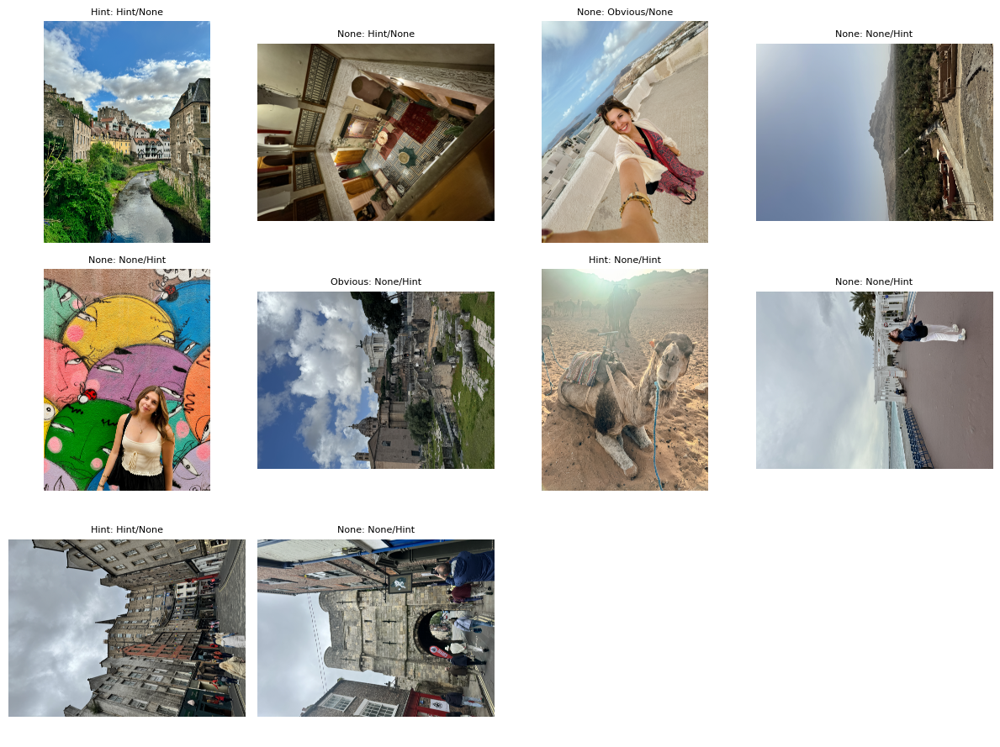

In [19]:
for f in FACETS:
    d, probs, classes = data[f], R[f]["probs"], R[f]["classes"]
    order = np.argsort(-probs, axis=1)
    idx = np.arange(len(d))
    d["top1"] = classes[order[:, 0]]
    d["top2"] = classes[order[:, 1]]
    d["margin"] = probs[idx, order[:, 0]] - probs[idx, order[:, 1]]
    d["entropy"] = -(probs * np.log(probs + 1e-12)).sum(axis=1)
    d["n_known"] = np.asarray((R[f]["vec"].transform(R[f]["X"]) > 0).sum(axis=1)).ravel()

def uncertain_items(f, k=10, between=None):
    d = data[f]
    if between is not None:
        a, b_ = between
        d = d[((d.top1 == a) & (d.top2 == b_)) | ((d.top1 == b_) & (d.top2 == a))]
    return d.sort_values("margin").head(k)

def show_uncertain(sub):
    display(sub[["filename", "label", "top1", "top2", "margin", "n_known", "text"]].round(3))
    show_images(sub, titles=[f"{l}: {a}/{b_}" for l, a, b_ in zip(sub.label, sub.top1, sub.top2)])

for f in FACETS:
    print("=" * 25, f, "=" * 25)
    show_uncertain(uncertain_items(f, 10))

Which pairs of classes the most uncertain items fall between, per facet, then a zoom-in on the top pair. Use `show_uncertain(uncertain_items(facet, 10, between=(a, b)))` for any other boundary.

========================= physical_setting =========================


,class 1,class 2,n uncertain items
0,Indoor,Urban,29
1,Nature,Urban,14
2,Coastal,Urban,9
3,Indoor,Nature,3
4,Coastal,Indoor,3
5,Coastal,Nature,2


,filename,label,top1,top2,margin,n_known,text
256,nice_image18.JPG,Coastal,Indoor,Urban,0.000,11,A woman poses at a wall overlooking Monaco's harbor and high-rises.
148,leeds_image14.jpg,Nature,Urban,Indoor,0.001,11,A woman in sunglasses and a leopard skirt poses in a festival crowd in front of a large stage.
29,barcelona_image27.JPG,Indoor,Indoor,Urban,0.006,10,"Two colorful poke-style bowls with steak, pickled onions, and greens, plus a pink juice."
117,genoa_image3.JPG,Indoor,Urban,Indoor,0.006,10,A handwritten chalkboard listing wines and spritz prices on a bar wall.
183,liverpool_image9.JPG,Urban,Indoor,Urban,0.018,7,Giant colorful letters spelling 'LIVERPOOL' along a paved waterfront walkway.
195,london_image21.JPG,Indoor,Urban,Indoor,0.021,13,A woman makes a surprised face in front of the glittering night view of London from high up.
65,dublin_image10.JPG,Urban,Indoor,Urban,0.062,13,"The Temple Bar pub at night, its facade covered in twinkling lights and hanging plants."
236,morocco_image15.JPG,Indoor,Indoor,Urban,0.064,13,"A colorful covered souk lane lined with textiles, bags, and souvenirs under carved wooden screens."


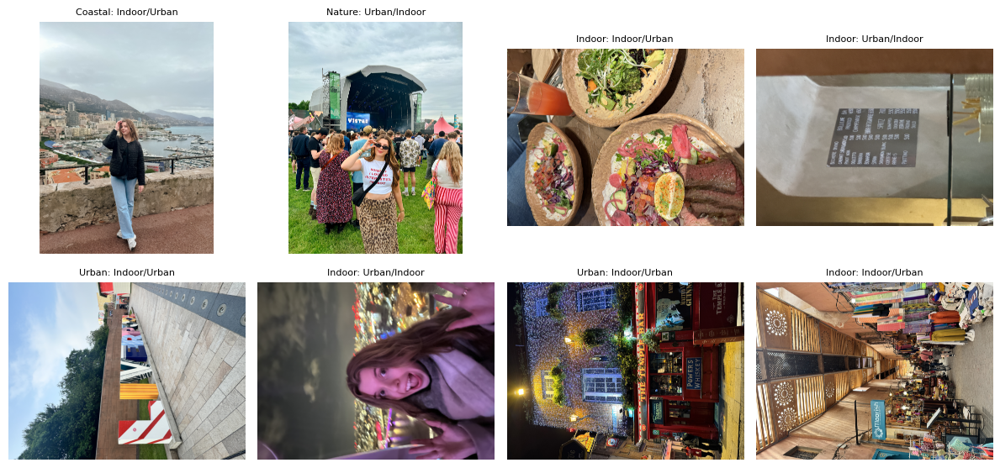

========================= activity =========================


,class 1,class 2,n uncertain items
0,Documenting the location,Tasting the location,27
1,Documenting the location,Putting myself in the frame,14
2,Documenting the location,Sharing the experience,11
3,Putting myself in the frame,Sharing the experience,5
4,Sharing the experience,Tasting the location,2
5,Documenting the location,Everyday life,1


,filename,label,top1,top2,margin,n_known,text
134,lake_image5.JPG,Tasting the location,Documenting the location,Tasting the location,0.009,7,Chocolate crêpes with raspberries and hazelnuts and a brownie with ice cream in speckled bowls.
271,rome_image26.JPG,Sharing the experience,Tasting the location,Documenting the location,0.024,9,Women in aprons whisk eggs and mascarpone while making tiramisu in a cooking class.
260,rome_image8.JPG,Tasting the location,Tasting the location,Documenting the location,0.038,9,Colorful cocktails including spritzes and mojitos with straws on a red tablecloth.
143,lake_image21.JPG,Documenting the location,Documenting the location,Tasting the location,0.046,12,"A pink-walled room in a historic house with an oil painting, large Imari vases, and a wooden chest."
268,rome_image20.JPG,Tasting the location,Documenting the location,Tasting the location,0.067,9,A hand holds up a cup of homemade tiramisu during a cooking class.
269,rome_image21.JPG,Tasting the location,Documenting the location,Tasting the location,0.085,7,Freshly made ravioli and tagliatelle on floured wooden boards at a pasta class.
99,florence_image24.JPG,Everyday life,Documenting the location,Tasting the location,0.126,12,A hand holds up a Kindle e-reader in a garden with bare trees and Tuscan hills behind.
267,rome_image19.JPG,Tasting the location,Documenting the location,Tasting the location,0.132,7,"Cooking-class workstations set with flour, eggs, rolling pins, and aprons."


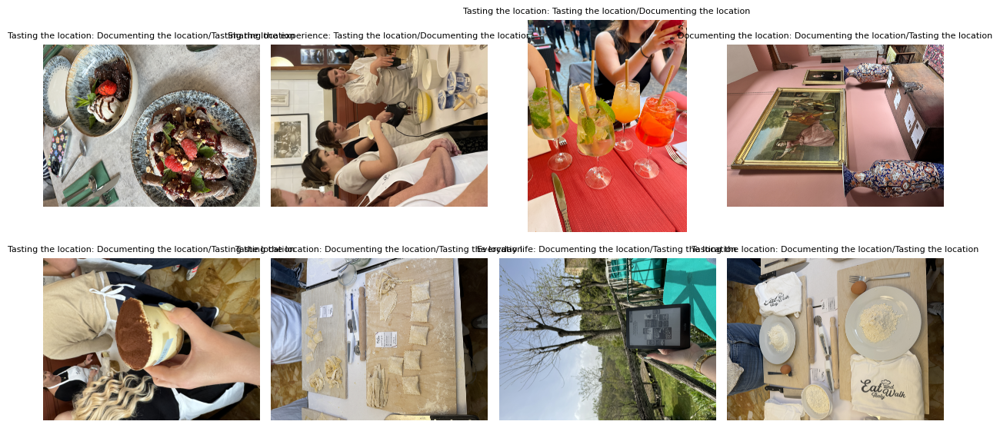

========================= subject =========================


,class 1,class 2,n uncertain items
0,Built,Nature,16
1,Built,Objects & Text,9
2,Food & Drink,Objects & Text,9
3,Built,Food & Drink,8
4,Built,People,4
5,Food & Drink,Nature,4


,filename,label,top1,top2,margin,n_known,text
201,madrid_image3.JPG,Food & Drink,Built,Nature,0.008,6,"A picnic spread on the grass with baguettes, chips, fruit, cured meats, and drinks."
142,lake_image20.JPG,Nature,Built,Nature,0.012,13,A herd of black-and-white cows gathers at a metal farm gate under a pink sunset sky.
228,morocco_image1.JPG,Built,Nature,Built,0.037,10,The earthen ksar of Aït Benhaddou on a hill above a green oasis and dry riverbed.
32,brussels_image6.JPG,Built,Nature,Built,0.043,14,The Gothic Brussels Town Hall towering over a busy Grand-Place on a cloudy day.
280,santorini_image10.JPG,Nature,Nature,Built,0.058,12,A wine glass on a terrace table overlooking the caldera under a cloudy sky.
107,galway_image13.JPG,Nature,Built,Nature,0.095,10,Sheer dark cliffs drop into the ocean with waves breaking at their base.
251,nice_image10.JPG,People,Nature,Built,0.129,12,A woman walks along the Promenade des Anglais past blue chairs and a white pergola.
297,york_image16.JPG,None/Other,Nature,Built,0.129,6,A cozy guesthouse bedroom with twin beds under low black-beamed ceilings.


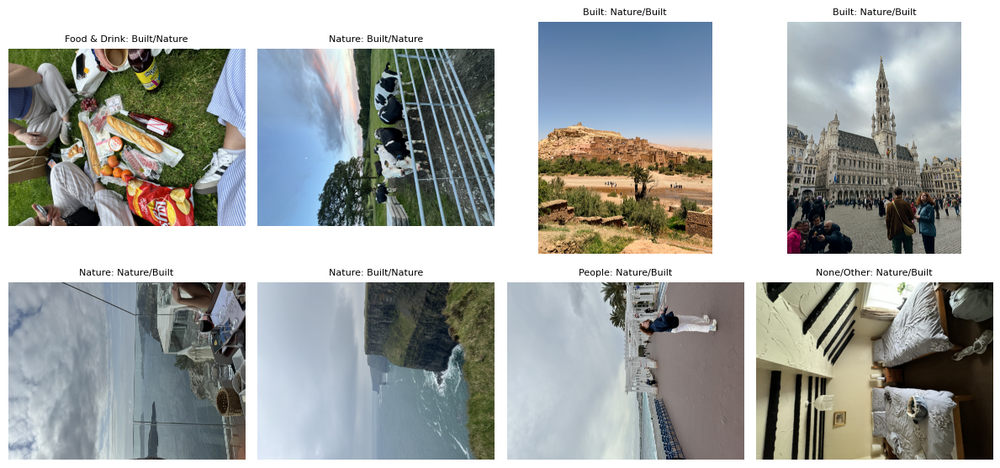

========================= place_recognizable =========================


,class 1,class 2,n uncertain items
0,Hint,None,42
1,None,Obvious,12
2,Hint,Obvious,6


,filename,label,top1,top2,margin,n_known,text
83,edinburgh_image18.JPG,Hint,Hint,None,0.001,8,The Water of Leith flowing past the old stone buildings of Dean Village.
233,morocco_image11.JPG,None,Hint,None,0.004,12,Looking down into the tiled courtyard of a traditional riad with carved balconies and rugs.
242,morocco_image25.JPG,None,None,Hint,0.005,8,A lush palm oasis stretches toward a rocky mountain under a hazy sky.
174,lisbon_image23.JPG,None,None,Hint,0.006,11,A woman stands in front of a colorful street-art mural of cartoon faces.
258,rome_image5.JPG,Obvious,None,Hint,0.010,6,The ruins of the Roman Forum with churches and the Vittoriano monument behind.
232,morocco_image8.JPG,Hint,None,Hint,0.012,10,"A saddled camel kneels on the sand looking at the camera, with a caravan behind in the haze."
251,nice_image10.JPG,None,None,Hint,0.017,12,A woman walks along the Promenade des Anglais past blue chairs and a white pergola.
79,edinburgh_image12.JPG,Hint,Hint,None,0.021,11,Tall old stone tenements tower over a busy cobbled street in Edinburgh's Old Town.


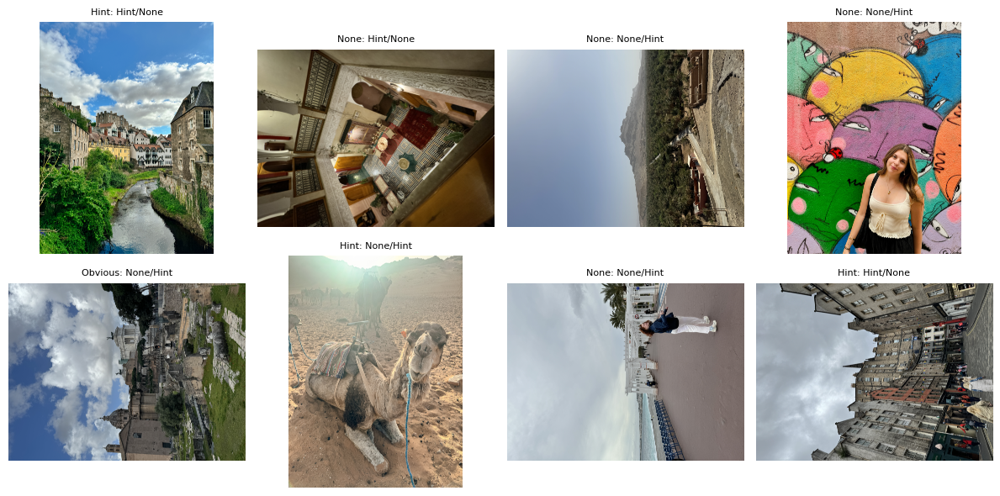

In [20]:
UNCERTAIN_N = 60      # look at this many of the most uncertain items per facet (out of 300)

for f in FACETS:
    unc = uncertain_items(f, UNCERTAIN_N)
    pc = Counter(tuple(sorted(p)) for p in zip(unc.top1, unc.top2))
    print("=" * 25, f, "=" * 25)
    display(pd.DataFrame([(a, b_, n) for (a, b_), n in pc.most_common(6)],
                         columns=["class 1", "class 2", "n uncertain items"]))
    (a, b_), _ = pc.most_common(1)[0]
    show_uncertain(uncertain_items(f, 8, between=(a, b_)))

The model's most confident mistakes per facet: high probability on a class that disagrees with the human label. Is the label wrong, the photo ambiguous, or the boundary the problem?

========================= physical_setting =========================


,filename,label,pred,p_pred,p_true,notes,text
213,marseille_image6.JPG,Coastal,Urban,0.871,0.036,,People stroll along the quay of Marseille's Old Port beside moored boats under puffy clouds.
270,rome_image23.JPG,Urban,Indoor,0.777,0.057,,Four friends pull silly faces in a selfie in St. Peter's Square.
144,lake_image24.JPG,Nature,Indoor,0.765,0.128,,"A rock garden full of ferns, purple and blue flowers, and a red Japanese maple."
57,cinque_image20.JPG,Coastal,Urban,0.761,0.156,,A woman in a blue sweater smiles at a railing with Manarola's colorful cliffside houses behind her.
215,marseille_image8.JPG,Urban,Indoor,0.759,0.110,,A latte with leaf art in a mint-green cup on a matching green café table.
77,edinburgh_image9.JPG,Indoor,Urban,0.728,0.185,,The vaulted Gothic nave of St Giles' Cathedral hung with colorful heraldic banners.
284,santorini_image18.JPG,Coastal,Indoor,0.704,0.081,,A wine-tasting flight of white and rosé wines with a cheese and charcuterie board.
90,florence_image10.JPG,Urban,Indoor,0.687,0.265,,"A hand holds two cannoli, pistachio and chocolate chip, in front of a pastry shop window."
16,barcelona_image3.JPG,Nature,Urban,0.673,0.126,,The ornate Cascada fountain in Parc de la Ciutadella reflected in a green pond.
36,brussels_image11.JPG,Urban,Coastal,0.670,0.048,,Two friends stand on a rooftop terrace with the Brussels skyline and clouds behind them.


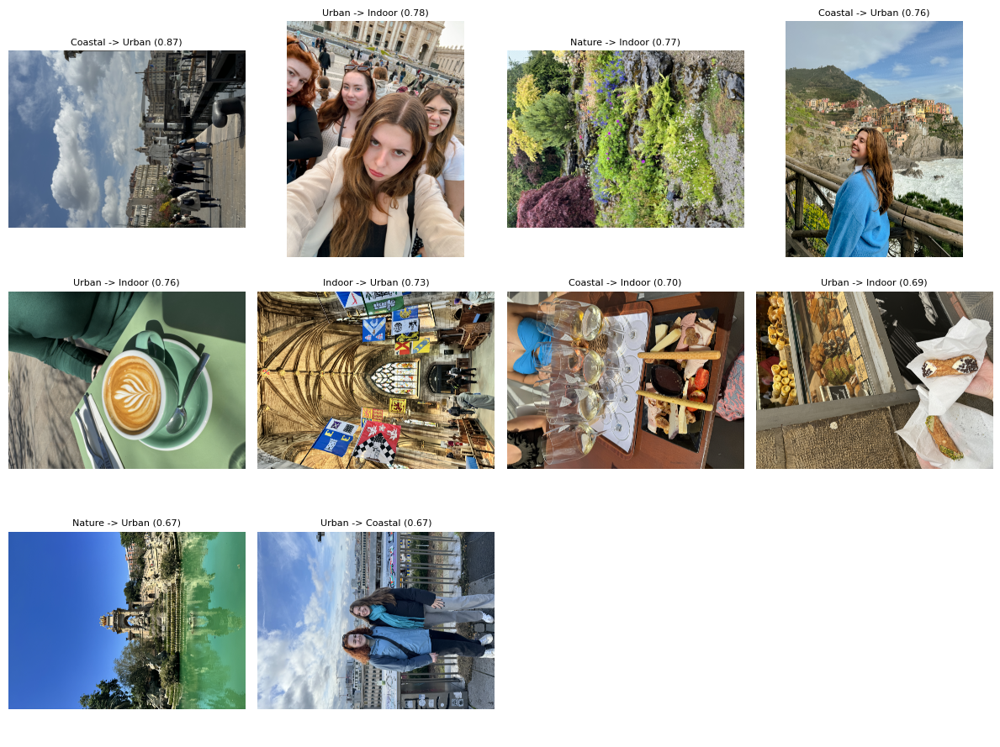

========================= activity =========================


,filename,label,pred,p_pred,p_true,notes,text
187,london_image5.JPG,Tasting the location,Documenting the location,0.914,0.054,,"An Indian feast of curries, naan, and rice at the Hichki restaurant."
171,lisbon_image18.JPG,Sharing the experience,Documenting the location,0.913,0.069,,Friends walk up a narrow street lined with pastel pink and yellow buildings.
198,london_image28.JPG,Sharing the experience,Documenting the location,0.892,0.057,,People with umbrellas walk past a grand stone museum facade under a golden sunset sky.
123,genoa_image12.JPG,Tasting the location,Documenting the location,0.887,0.064,,Two hands hold small pastries topped with bright green pesto.
241,morocco_image24.JPG,Sharing the experience,Documenting the location,0.879,0.041,,Point-of-view from a camel saddle following a line of riders across the desert.
42,brussels_image18.JPG,Sharing the experience,Documenting the location,0.852,0.057,,Visitors look up at a ring of glowing light tubes inside one of the Atomium's spheres.
122,genoa_image11.JPG,Documenting the location,Tasting the location,0.840,0.111,,"A pesto shop counter with a pasta machine, mortars on shelves, and a Pestobene ingredients poster."
252,nice_image11.JPG,Everyday life,Documenting the location,0.837,0.025,,Shoppers browse market stalls under striped awnings in Nice's Cours Saleya.
297,york_image16.JPG,Everyday life,Documenting the location,0.831,0.028,,A cozy guesthouse bedroom with twin beds under low black-beamed ceilings.
152,leeds_image20.JPG,Everyday life,Documenting the location,0.827,0.004,,"A pedestrian walkway on a university campus lined with red-brick buildings, bikes, and bunting."


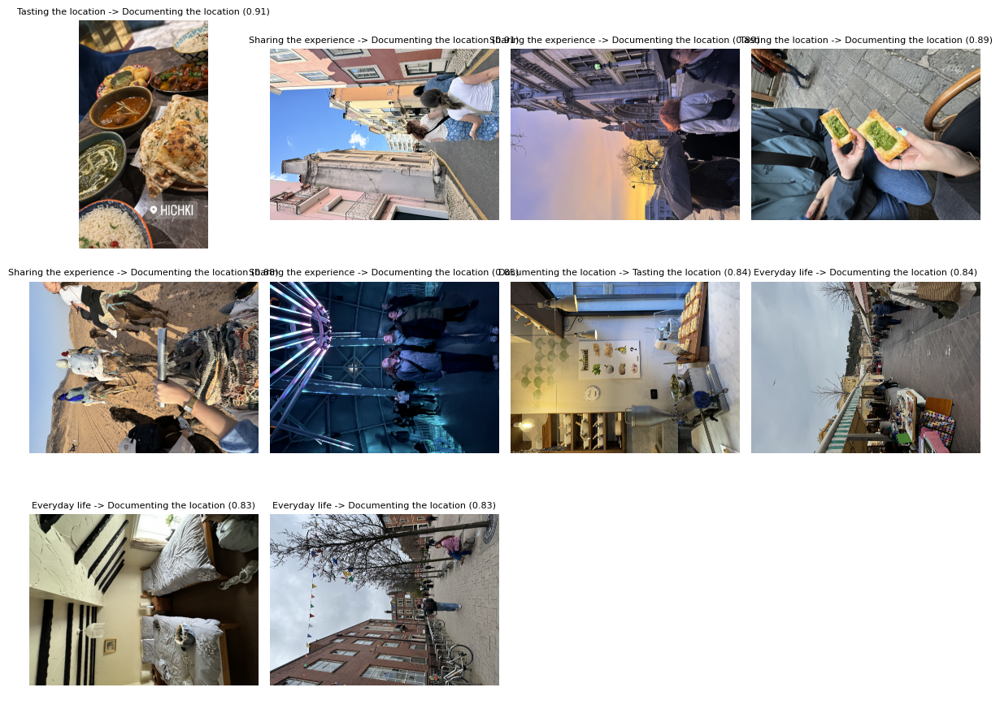

========================= subject =========================


,filename,label,pred,p_pred,p_true,notes,text
161,lisbon_image2.JPG,Nature,People,0.904,0.016,,A woman in a denim jacket walks past market stalls on a tree-lined Lisbon boulevard.
69,dublin_image15.JPG,Objects & Text,Built,0.892,0.028,,The arched entrance of the Jameson Distillery on Bow Street.
253,nice_image13.JPG,Nature,Built,0.862,0.036,,The sweeping curve of the Baie des Anges and the city of Nice seen from above.
72,edinburgh_image1.JPG,Built,Nature,0.841,0.102,,Edinburgh Castle on its rocky crag seen above green trees under a gray sky.
38,brussels_image13.JPG,Built,Objects & Text,0.821,0.098,,Neon signs glow over the crowded entrance of the Delirium bar on a narrow street at night.
13,amalfi_image21.JPG,Nature,Built,0.782,0.128,,"Sun breaking through clouds over the sea, seen from high above terraced coastal houses."
184,london_image1.JPG,People,Built,0.771,0.026,,Crowds browse food stalls under strings of flags at the Ropewalk market beneath railway arches.
255,nice_image15.JPG,Nature,Built,0.764,0.149,,"View of the Baie des Anges and Nice's red rooftops from Castle Hill, framed by branches."
223,marseille_image26.JPG,Nature,Built,0.751,0.111,,Looking down a narrow calanque inlet lined with moored sailboats and pine forest.
189,london_image9.JPG,None/Other,People,0.749,0.058,"friend from behind at the arcade game, no face; None/Other vs Objects & Text as subject.","A woman shoots hoops at an arcade basketball game in a dim, blue-lit room."


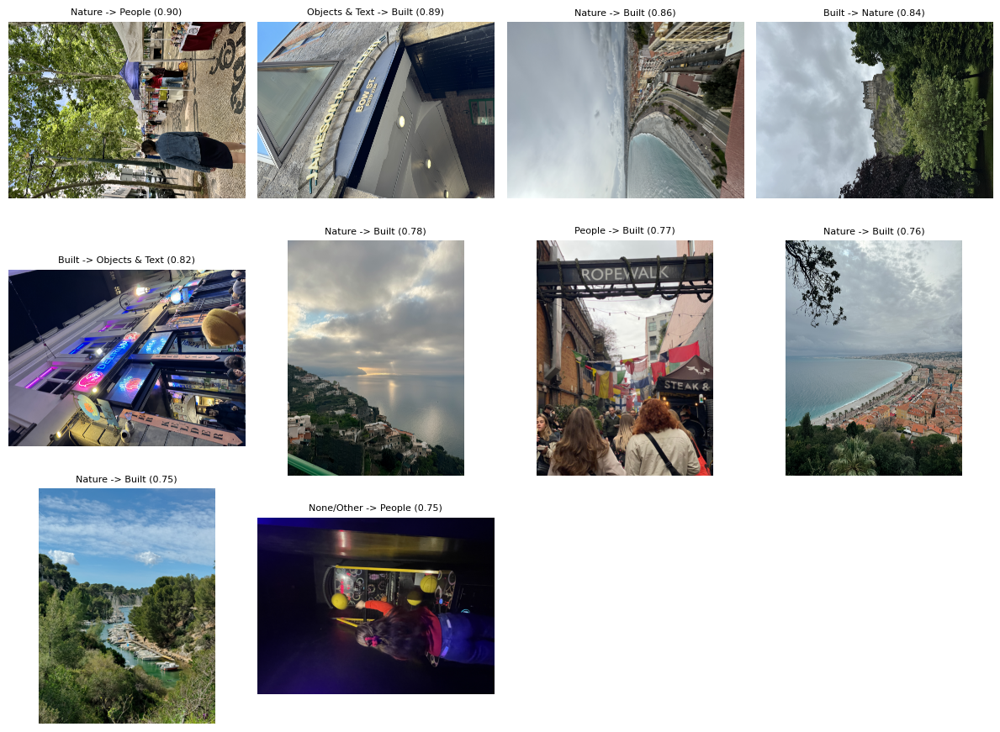

========================= place_recognizable =========================


,filename,label,pred,p_pred,p_true,notes,text
277,santorini_image7.JPG,Hint,None,0.989,0.009,,Two people walk down a narrow lane between cream-colored walls at dusk.
74,edinburgh_image5.JPG,Hint,None,0.977,0.017,,Visitors pass through a stone gatehouse between high castle walls at Edinburgh Castle.
266,rome_image18.JPG,Hint,None,0.977,0.020,,A smiling woman holds up a 'Calendario Romano' calendar of black-and-white priest portraits.
188,london_image7.JPG,Hint,None,0.972,0.017,,Three friends take a selfie inside a London Eye capsule with the city lit up at night.
238,morocco_image17.JPG,Hint,None,0.971,0.019,,"A carved, painted pavilion ceiling framing a tiled fountain and garden in Marrakech."
236,morocco_image15.JPG,Hint,None,0.964,0.033,,"A colorful covered souk lane lined with textiles, bags, and souvenirs under carved wooden screens."
175,liverpool_image1.JPG,Hint,None,0.929,0.044,,The red wrought-iron Strawberry Field gates set in a stone wall under green trees.
279,santorini_image9.JPG,Obvious,None,0.929,0.036,,A Greek flag between two Santo Wines flags on a terrace above the sea.
183,liverpool_image9.JPG,Obvious,None,0.927,0.004,,Giant colorful letters spelling 'LIVERPOOL' along a paved waterfront walkway.
210,madrid_image12.JPG,Hint,None,0.920,0.071,,A pan of seafood paella with olives and a small cazuela dish on a restaurant table.


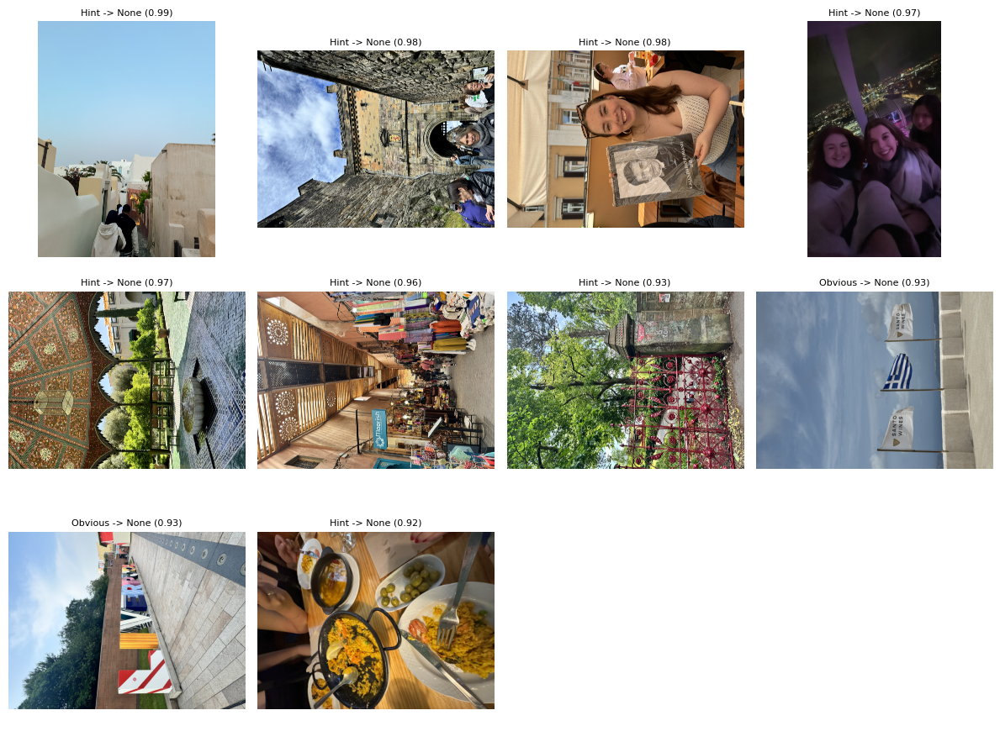

In [21]:
K_WRONG = 10
for f in FACETS:
    d = data[f]
    wrong = d[d.pred != d.label].sort_values("p_pred", ascending=False).head(K_WRONG)
    print("=" * 25, f, "=" * 25)
    display(wrong[["filename", "label", "pred", "p_pred", "p_true", "notes", "text"]].round(3))
    show_images(wrong, titles=[f"{l} -> {p} ({q:.2f})" for l, p, q in zip(wrong.label, wrong.pred, wrong.p_pred)])

## Part 7: Comparing facets

One table across all facets: how far above the majority baseline each facet's classifier gets, and its macro F1. Plus, for each photo, how many facets the model got right (photos that are wrong in several facets at once).

In [22]:
macro = {f: classification_report(R[f]["y"], R[f]["pred"], output_dict=True, zero_division=0)["macro avg"]["f1-score"]
         for f in FACETS}
comp = summary.copy()
comp["gain over baseline"] = comp["CV accuracy"] - comp["majority baseline"]
comp["macro F1"] = pd.Series(macro)
display(comp.round(3))

right = pd.DataFrame({f: data[f].set_index("filename").eval("label == pred") for f in FACETS})
right["n facets right"] = right.sum(axis=1)
right["n facets scored"] = right[FACETS].notna().sum(axis=1)
print(right["n facets right"].value_counts().sort_index().to_string())
all_wrong = right[right["n facets right"] == 0].index
print(len(all_wrong), "photos wrong in every facet:")
display(df[df.filename.isin(all_wrong)][["filename"] + FACETS + ["text"]])

,n items,n classes,majority class,majority baseline,CV accuracy,gain over baseline,macro F1
facet,,,,,,,
physical_setting,300,4,Urban,0.363,0.707,0.343,0.693
activity,300,5,Documenting the location,0.497,0.857,0.360,0.688
subject,300,6,People,0.280,0.743,0.463,0.569
place_recognizable,300,3,None,0.607,0.593,-0.013,0.462


n facets right
0      1
1     21
2     66
3    131
4     81
1 photos wrong in every facet:


,filename,physical_setting,activity,subject,place_recognizable,text
187,london_image5.JPG,Indoor,Tasting the location,Food & Drink,None,"An Indian feast of curries, naan, and rice at the Hichki restaurant."


## Part 8: Scaling classification to the full collection

The cross-validated results in Parts 2 to 7 are the evaluation: every hand-labeled photo was scored by a model that never saw it, so those numbers estimate how well each facet's classifier does on photos it hasn't seen. Here one model per facet is trained on all hand-labeled photos and used to label the rest of the collection (the photos with `in_sample == "no"`). The output file can be fed to the faceted browser if you want model labels for the unlabeled photos.

In [23]:
full = raw.copy()
full["text"] = full[TEXT_COL].str.replace("\\t", " ").str.replace("\\n", " ")
full["hand_labeled"] = full.in_sample.str.lower() == "yes"
unlabeled = full[~full.hand_labeled].copy()
print(len(full), "photos in the collection;", full.hand_labeled.sum(), "hand-labeled;", len(unlabeled), "to label with the model")

for f in FACETS:
    m = make_model().fit(R[f]["X"], R[f]["y"])
    p = m.predict_proba(unlabeled.text.to_list())
    unlabeled[f + "_pred"] = m.classes_[p.argmax(axis=1)]
    unlabeled[f + "_prob"] = p.max(axis=1)

for f in FACETS:
    print("=" * 25, f, "=" * 25)
    comp_dist = pd.DataFrame({
        "hand-labeled sample (share)": data[f].label.value_counts(normalize=True),
        "model on unlabeled (share)": unlabeled[f + "_pred"].value_counts(normalize=True),
    }).fillna(0)
    display(comp_dist.round(3))

OUT_PRED = "predicted_facets_unlabeled.csv"
cols = ["filename", "country", "stop", "text"] + [c for f in FACETS for c in (f + "_pred", f + "_prob")]
unlabeled[cols].to_csv(OUT_PRED, index=False)
print("saved", OUT_PRED)

485 photos in the collection; 300 hand-labeled; 185 to label with the model
========================= physical_setting =========================


,hand-labeled sample (share),model on unlabeled (share)
Urban,0.363,0.400
Indoor,0.317,0.357
Coastal,0.163,0.124
Nature,0.157,0.119


========================= activity =========================


,hand-labeled sample (share),model on unlabeled (share)
Documenting the location,0.497,0.551
Everyday life,0.027,0.000
Putting myself in the frame,0.143,0.151
Sharing the experience,0.167,0.157
Tasting the location,0.167,0.141


========================= subject =========================


,hand-labeled sample (share),model on unlabeled (share)
People,0.280,0.335
Built,0.280,0.232
Food & Drink,0.163,0.173
Nature,0.140,0.135
Objects & Text,0.117,0.119
None/Other,0.020,0.005


========================= place_recognizable =========================


,hand-labeled sample (share),model on unlabeled (share)
None,0.607,0.773
Hint,0.257,0.178
Obvious,0.137,0.049


saved predicted_facets_unlabeled.csv


The least confident model labels on the unlabeled photos, per facet (low `_prob` = the model's guess is weakest). Worth spot-checking a few of these by eye against your codebook.

========================= physical_setting =========================


,filename,physical_setting_pred,physical_setting_prob,text
129,florence_image1.JPG,Nature,0.285,A red chair on a daisy-covered lawn with Tuscan hills and a villa in the distance.
154,galway_image1.JPG,Urban,0.303,Two friends stand on a rocky shoreline beside the gray waters of Galway Bay.
316,london_image15.JPG,Urban,0.322,"Korean barbecue with grilled pork on a hot stone, lettuce wraps, and dipping sauces."
232,leeds_image10.JPG,Nature,0.334,The Hyde Park Picture House logo projected on a cinema screen in the dark.
349,marseille_image4.JPG,Urban,0.340,A woman hikes a gravel trail through a limestone gorge in the Calanques.
156,galway_image3.JPG,Coastal,0.351,The colorful houses of the Long Walk across the river from a green bank in Galway.
216,lake_image18.JPG,Indoor,0.360,The swinging sign of The Black Labrador pub above a flower bed.
3,amalfi_image4.JPG,Nature,0.363,Rows of young grapevines in a sunny hillside vineyard with mountains on the horizon.


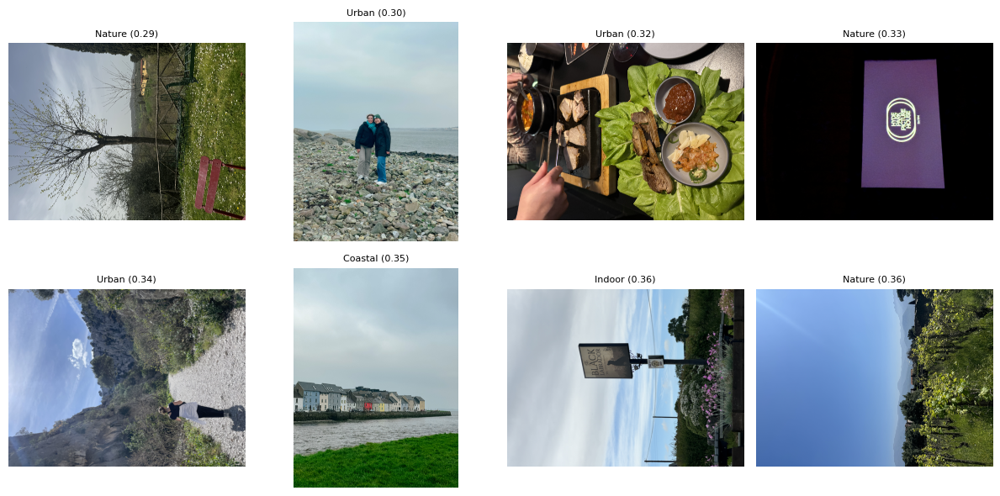

========================= activity =========================


,filename,activity_pred,activity_prob,text
347,marseille_image2.JPG,Sharing the experience,0.313,A woman walks along a narrow sidewalk past La Table du Fort on a sunlit street.
184,genoa_image5.JPG,Tasting the location,0.390,"A hand holds a crusty sandwich filled with cured meat, wrapped in paper."
311,london_image10.JPG,Putting myself in the frame,0.434,A woman sips a drink through a straw from a teapot under red lighting.
350,marseille_image5.JPG,Documenting the location,0.436,A woman walks along a white gravel path beneath rugged limestone cliffs.
76,cinque_image7.JPG,Sharing the experience,0.440,A woman in a blue sweater walks up a stone alley past a pixel-art mural of a walking figure.
250,leeds_image28.JPG,Tasting the location,0.450,"A laptop playing a show beside a coffee cup on a small table by a window, legs crossed in front."
316,london_image15.JPG,Tasting the location,0.467,"Korean barbecue with grilled pork on a hot stone, lettuce wraps, and dipping sauces."
187,genoa_image8.JPG,Documenting the location,0.469,"A pizza topped with tomato sauce, pesto, and burrata in a takeaway box next to cans of Coca-Cola."


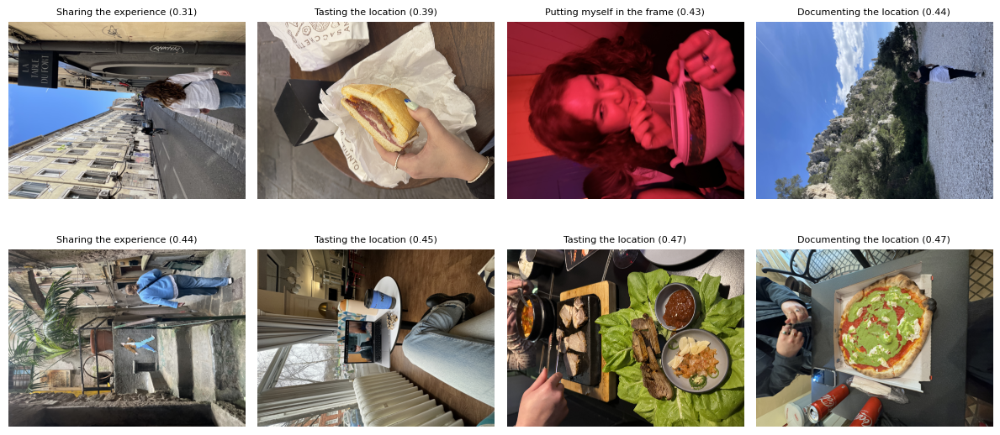

========================= subject =========================


,filename,subject_pred,subject_prob,text
129,florence_image1.JPG,Objects & Text,0.225,A red chair on a daisy-covered lawn with Tuscan hills and a villa in the distance.
3,amalfi_image4.JPG,Food & Drink,0.243,Rows of young grapevines in a sunny hillside vineyard with mountains on the horizon.
130,florence_image2.JPG,Objects & Text,0.275,A red bistro table and chairs on the grass outside a brick garden cottage.
28,barcelona_image6.JPG,Nature,0.299,Looking up at a shopfront entrance decorated with pink and white flower garlands.
273,lisbon_image4.jpg,Nature,0.314,Purple jacaranda trees bloom over a wavy-patterned plaza with a pink tuk-tuk.
449,santorini_image1.JPG,Food & Drink,0.316,A whitewashed cave-style hotel room with a blue-cushioned sofa and arched ceiling.
269,leeds_image47.JPG,People,0.320,A person in a black hat dances under bright purple club lights.
391,morocco_image13.JPG,Food & Drink,0.325,"A Moroccan breakfast spread of msemen flatbread, croissants, jams, olives, and orange juice."


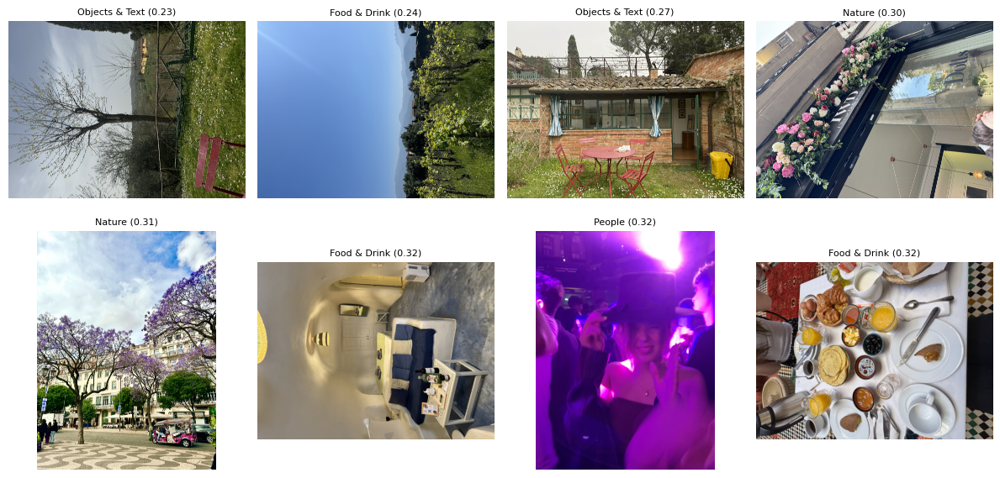

========================= place_recognizable =========================


,filename,place_recognizable_pred,place_recognizable_prob,text
246,leeds_image24.JPG,Obvious,0.348,"The red, light-strung outdoor terrace of the Hyde Park Book Club bar at night with picnic tables."
216,lake_image18.JPG,None,0.376,The swinging sign of The Black Labrador pub above a flower bed.
387,morocco_image9.JPG,Hint,0.401,Riders in white sit on a line of camels in front of a desert tent camp on the sand.
154,galway_image1.JPG,Hint,0.409,Two friends stand on a rocky shoreline beside the gray waters of Galway Bay.
157,galway_image4.JPG,Obvious,0.432,Three friends pose on a grassy riverbank with the Long Walk's colorful houses behind them.
156,galway_image3.JPG,Obvious,0.446,The colorful houses of the Long Walk across the river from a green bank in Galway.
194,genoa_image15.JPG,Obvious,0.448,Wide view of Piazza De Ferrari's fountains in front of the ornate Palazzo della Borsa.
44,barcelona_image22.JPG,Obvious,0.455,"The colorful, scale-like facade of Gaudí's Casa Batlló with crowds at the entrance."


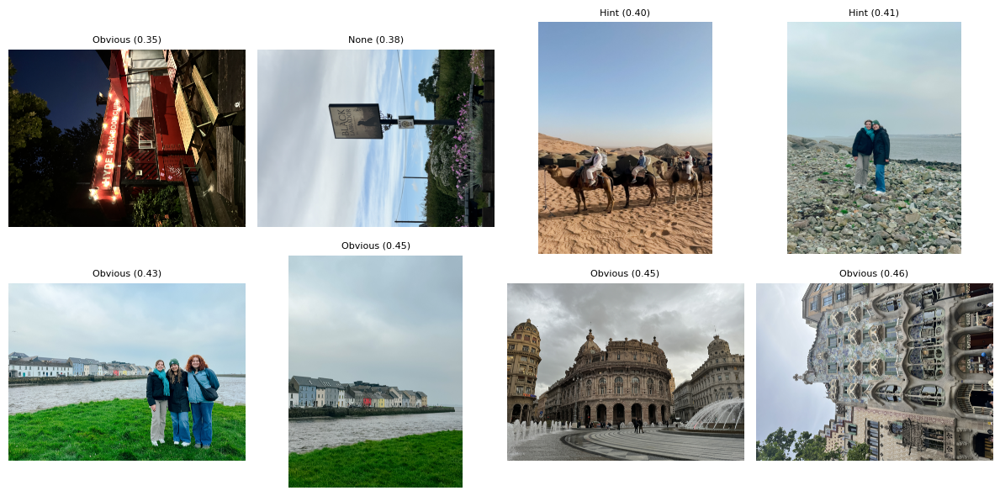

In [24]:
for f in FACETS:
    print("=" * 25, f, "=" * 25)
    sub = unlabeled.sort_values(f + "_prob").head(8)
    display(sub[["filename", f + "_pred", f + "_prob", "text"]].round(3))
    if HAVE_IMAGES:
        sub = sub.assign(path=[find_image(fn) for fn in sub.filename])
        if sub.path.notna().all():
            show_images(sub, titles=[f"{p} ({q:.2f})" for p, q in zip(sub[f + "_pred"], sub[f + "_prob"])])

### Export predicted labels to CSV

One row per photo in the collection: the filename, whether you hand-labeled it, and the model's predicted label for each facet. For the hand-labeled photos the prediction is the cross-validated one from Part 2 (from a model that never saw that photo); for the rest it's the prediction from Part 8. In Colab the file also downloads automatically.

In [25]:
OUT_CSV = "predicted_labels.csv"

pred_table = full[["filename", "hand_labeled"]].copy()
for f in FACETS:
    cv_pred = data[f].set_index("filename")["pred"]                 # hand-labeled photos (cross-validated)
    rest_pred = unlabeled.set_index("filename")[f + "_pred"]        # photos not hand-labeled
    pred_table[f + "_pred"] = pred_table.filename.map(cv_pred).fillna(pred_table.filename.map(rest_pred))

pred_table["hand_labeled"] = pred_table.hand_labeled.map({True: "yes", False: "no"})
pred_table.to_csv(OUT_CSV, index=False)
print("saved", OUT_CSV, "with", len(pred_table), "rows")
display(pred_table.head(10))

if IN_COLAB:
    from google.colab import files
    files.download(OUT_CSV)

saved predicted_labels.csv with 485 rows


,filename,hand_labeled,physical_setting_pred,activity_pred,subject_pred,place_recognizable_pred
0,amalfi_image1.JPG,no,Coastal,Documenting the location,Nature,None
1,amalfi_image2.JPG,yes,Coastal,Putting myself in the frame,People,Hint
2,amalfi_image3.JPG,no,Coastal,Putting myself in the frame,People,None
3,amalfi_image4.JPG,no,Nature,Documenting the location,Food & Drink,None
4,amalfi_image5.JPG,yes,Indoor,Documenting the location,Objects & Text,None
5,amalfi_image6.JPG,yes,Coastal,Putting myself in the frame,People,None
6,amalfi_image7.JPG,yes,Indoor,Tasting the location,Food & Drink,None
7,amalfi_image8.JPG,yes,Coastal,Documenting the location,Nature,None
8,amalfi_image9.JPG,no,Indoor,Tasting the location,Food & Drink,None
9,amalfi_image10.JPG,yes,Indoor,Documenting the location,Nature,None


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>